In [1]:
# ============================================================
# NOTEBOOK 05
# FINAL NASA TEST EVALUATION
# ============================================================
# Goals:
#
# 1. Load saved preprocessing artifacts
# 2. Load final CAUC-AeroRULNet models
# 3. Evaluate untouched NASA test engines
# 4. Calculate final research metrics
# 5. Build maintenance decision layer
#
# IMPORTANT:
# No model tuning is allowed in this notebook.
# ============================================================

import os
import joblib

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import tensorflow as tf

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("TensorFlow Version:", tf.__version__)
print("Notebook 05 libraries loaded successfully.")

TensorFlow Version: 2.21.0
Notebook 05 libraries loaded successfully.


In [2]:
# ============================================================
# PROJECT PATHS
# ============================================================

PROJECT_DIR = r"D:\IST\Aircraft_Engine_RUL"

CHECKPOINT_DIR = os.path.join(
    PROJECT_DIR,
    "checkpoints"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

RESULT_DIR = os.path.join(
    PROJECT_DIR,
    "results"
)

DATA_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "raw"
)


print("Project Directory:")
print(PROJECT_DIR)

print("\nCheckpoint Directory:")
print(CHECKPOINT_DIR)

print("\nModel Directory:")
print(MODEL_DIR)

Project Directory:
D:\IST\Aircraft_Engine_RUL

Checkpoint Directory:
D:\IST\Aircraft_Engine_RUL\checkpoints

Model Directory:
D:\IST\Aircraft_Engine_RUL\models


In [3]:
# ============================================================
# LOAD FINAL PROJECT CONFIGURATION
# ============================================================

FINAL_CONFIG_PATH = os.path.join(
    CHECKPOINT_DIR,
    "final_project_config.pkl"
)


if not os.path.exists(
    FINAL_CONFIG_PATH
):
    raise FileNotFoundError(
        f"Final project config not found:\n"
        f"{FINAL_CONFIG_PATH}"
    )


final_project_config = joblib.load(
    FINAL_CONFIG_PATH
)


print("=" * 60)
print("FINAL PROJECT CONFIGURATION")
print("=" * 60)

for key, value in final_project_config.items():
    print(
        f"{key}: {value}"
    )

FINAL PROJECT CONFIGURATION
sequence_length: 50
num_sensors: 16
learning_rate: 0.0005
dropout: 0.2
selected_sensors: ['sensor_11', 'sensor_17', 'sensor_4', 'sensor_3', 'sensor_2', 'sensor_9', 'sensor_13', 'sensor_8', 'sensor_14', 'sensor_15', 'sensor_12', 'sensor_7', 'sensor_20', 'sensor_21', 'sensor_6', 'sensor_10']


In [4]:
# ============================================================
# RESTORE FINAL CONFIGURATION VALUES
# ============================================================

SEQUENCE_LENGTH = (
    final_project_config[
        "sequence_length"
    ]
)

FINAL_LEARNING_RATE = (
    final_project_config[
        "learning_rate"
    ]
)

FINAL_DROPOUT = (
    final_project_config[
        "dropout"
    ]
)


print(
    "Final Sequence Length:",
    SEQUENCE_LENGTH
)

print(
    "Final Learning Rate:",
    FINAL_LEARNING_RATE
)

print(
    "Final Dropout:",
    FINAL_DROPOUT
)

Final Sequence Length: 50
Final Learning Rate: 0.0005
Final Dropout: 0.2


In [5]:
# ============================================================
# LOAD PREPROCESSING / DEEP LEARNING CHECKPOINT
# ============================================================

DL_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "phase_02_deep_learning_checkpoint.joblib"
)


if not os.path.exists(
    DL_CHECKPOINT_PATH
):
    raise FileNotFoundError(
        f"DL checkpoint not found:\n"
        f"{DL_CHECKPOINT_PATH}"
    )


dl_checkpoint = joblib.load(
    DL_CHECKPOINT_PATH
)


print(
    "✅ Deep Learning checkpoint loaded."
)

print(
    "Saved Objects:",
    len(dl_checkpoint)
)

✅ Deep Learning checkpoint loaded.
Saved Objects: 20


In [6]:
# ============================================================
# RESTORE PREPROCESSING ARTIFACTS
# ============================================================
# These objects were fitted using training data only.
#
# They must be reused for official NASA test data.
# ============================================================

model_sensor_cols = dl_checkpoint[
    "model_sensor_cols"
]


# FD002 operating-condition scaler
fd002_op_scaler_model = dl_checkpoint[
    "fd002_op_scaler_model"
]


# FD002 operating-condition clustering model
fd002_kmeans_model = dl_checkpoint[
    "fd002_kmeans_model"
]


# FD002 condition-wise sensor statistics
fd002_model_condition_means = dl_checkpoint[
    "fd002_model_condition_means"
]

fd002_model_safe_stds = dl_checkpoint[
    "fd002_model_safe_stds"
]


# FD003 training statistics
fd003_model_means = dl_checkpoint[
    "fd003_model_means"
]

fd003_model_safe_stds = dl_checkpoint[
    "fd003_model_safe_stds"
]


print(
    "Number of model sensors:",
    len(model_sensor_cols)
)

print("\nModel Sensor Columns:")

print(
    model_sensor_cols
)

Number of model sensors: 16

Model Sensor Columns:
['sensor_2_model_norm', 'sensor_3_model_norm', 'sensor_4_model_norm', 'sensor_6_model_norm', 'sensor_7_model_norm', 'sensor_8_model_norm', 'sensor_9_model_norm', 'sensor_10_model_norm', 'sensor_11_model_norm', 'sensor_12_model_norm', 'sensor_13_model_norm', 'sensor_14_model_norm', 'sensor_15_model_norm', 'sensor_17_model_norm', 'sensor_20_model_norm', 'sensor_21_model_norm']


In [7]:
# ============================================================
# SERIALIZATION-SAFE TEMPORAL SUM LAYER
# ============================================================

@tf.keras.utils.register_keras_serializable(
    package="CAUC"
)
class TemporalSum(
    tf.keras.layers.Layer
):

    def call(
        self,
        inputs
    ):

        return tf.reduce_sum(
            inputs,
            axis=1
        )


    def compute_output_shape(
        self,
        input_shape
    ):

        return (
            input_shape[0],
            input_shape[2]
        )


    def get_config(
        self
    ):

        return super().get_config()


print(
    "✅ TemporalSum layer registered."
)

✅ TemporalSum layer registered.


In [8]:
# ============================================================
# FINAL CAUC MODEL PATHS
# ============================================================

FD002_FINAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "cauc_aerorulnet_fd002_final.keras"
)


FD003_FINAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "cauc_aerorulnet_fd003_final.keras"
)


print(
    "FD002 Model Exists:",
    os.path.exists(
        FD002_FINAL_MODEL_PATH
    )
)

print(
    "FD003 Model Exists:",
    os.path.exists(
        FD003_FINAL_MODEL_PATH
    )
)

FD002 Model Exists: True
FD003 Model Exists: True


In [9]:
# ============================================================
# LOAD FINAL CAUC-AeroRULNet MODELS
# ============================================================

final_cauc_fd002 = (
    tf.keras.models.load_model(
        FD002_FINAL_MODEL_PATH,
        custom_objects={
            "TemporalSum": TemporalSum
        },
        compile=False
    )
)


final_cauc_fd003 = (
    tf.keras.models.load_model(
        FD003_FINAL_MODEL_PATH,
        custom_objects={
            "TemporalSum": TemporalSum
        },
        compile=False
    )
)


print(
    "✅ Both final CAUC models loaded."
)

✅ Both final CAUC models loaded.


In [10]:
# ============================================================
# FINAL MODEL VERIFICATION
# ============================================================

EXPECTED_PARAMS = 97378


print("=" * 65)

print(
    "FINAL CAUC MODEL VERIFICATION"
)

print("=" * 65)


print(
    "FD002 Parameters:",
    final_cauc_fd002.count_params()
)


print(
    "FD003 Parameters:",
    final_cauc_fd003.count_params()
)


if (
    final_cauc_fd002.count_params()
    == EXPECTED_PARAMS

    and

    final_cauc_fd003.count_params()
    == EXPECTED_PARAMS
):

    print(
        "\n✅ Both final CAUC models verified successfully."
    )

else:

    print(
        "\n❌ Parameter mismatch detected."
    )

FINAL CAUC MODEL VERIFICATION
FD002 Parameters: 97378
FD003 Parameters: 97378

✅ Both final CAUC models verified successfully.


In [11]:
# ============================================================
# LOAD SAVED VALIDATION RESULTS
# ============================================================

VALIDATION_METRICS_PATH = os.path.join(
    CHECKPOINT_DIR,
    "final_validation_metrics.pkl"
)


final_validation_metrics = joblib.load(
    VALIDATION_METRICS_PATH
)


print(
    "✅ Validation metrics loaded."
)


print(
    "\nFD002 Validation:"
)

print(
    final_validation_metrics[
        "FD002"
    ]
)


print(
    "\nFD003 Validation:"
)

print(
    final_validation_metrics[
        "FD003"
    ]
)

✅ Validation metrics loaded.

FD002 Validation:
{'BiLSTM': {'MAE': 9.973058, 'RMSE': 14.169504, 'R2': 0.880206}, 'CAUC-AeroRULNet': {'MAE': 10.469964, 'RMSE': 13.462717, 'R2': 0.891859}}

FD003 Validation:
{'BiLSTM': {'MAE': 8.270232, 'RMSE': 11.366003, 'R2': 0.926313}, 'CAUC-AeroRULNet': {'MAE': 8.556795, 'RMSE': 11.31401, 'R2': 0.926985}}


In [12]:
# ============================================================
# OFFICIAL NASA C-MAPSS TEST PATHS
# ============================================================

FD002_TEST_PATH = os.path.join(
    DATA_DIR,
    "FD002",
    "test_FD002.txt"
)

FD002_RUL_PATH = os.path.join(
    DATA_DIR,
    "FD002",
    "RUL_FD002.txt"
)


FD003_TEST_PATH = os.path.join(
    DATA_DIR,
    "FD003",
    "test_FD003.txt"
)

FD003_RUL_PATH = os.path.join(
    DATA_DIR,
    "FD003",
    "RUL_FD003.txt"
)


print(
    "FD002 Test Exists:",
    os.path.exists(
        FD002_TEST_PATH
    )
)

print(
    "FD002 RUL Exists:",
    os.path.exists(
        FD002_RUL_PATH
    )
)

print(
    "FD003 Test Exists:",
    os.path.exists(
        FD003_TEST_PATH
    )
)

print(
    "FD003 RUL Exists:",
    os.path.exists(
        FD003_RUL_PATH
    )
)

FD002 Test Exists: False
FD002 RUL Exists: False
FD003 Test Exists: False
FD003 RUL Exists: False


In [13]:
# ============================================================
# FIND NASA C-MAPSS TEST / RUL FILES AUTOMATICALLY
# ============================================================
# Purpose:
# Search the complete project folder recursively and find
# actual locations of FD002 / FD003 test and RUL files.
# ============================================================

import os

PROJECT_DIR = r"D:\IST\Aircraft_Engine_RUL"


target_names = [
    "test_FD002.txt",
    "RUL_FD002.txt",
    "test_FD003.txt",
    "RUL_FD003.txt"
]


found_files = {}


for root, dirs, files in os.walk(PROJECT_DIR):

    for file_name in files:

        if file_name in target_names:

            full_path = os.path.join(
                root,
                file_name
            )

            found_files[
                file_name
            ] = full_path


print("=" * 70)
print("NASA FILE SEARCH RESULTS")
print("=" * 70)


for target in target_names:

    if target in found_files:

        print(
            f"✅ {target}"
        )

        print(
            found_files[target]
        )

        print()

    else:

        print(
            f"❌ {target} NOT FOUND"
        )

        print()

NASA FILE SEARCH RESULTS
✅ test_FD002.txt
D:\IST\Aircraft_Engine_RUL\data\raw\test_FD002.txt

✅ RUL_FD002.txt
D:\IST\Aircraft_Engine_RUL\data\raw\RUL_FD002.txt

✅ test_FD003.txt
D:\IST\Aircraft_Engine_RUL\data\raw\test_FD003.txt

✅ RUL_FD003.txt
D:\IST\Aircraft_Engine_RUL\data\raw\RUL_FD003.txt



In [14]:
# ============================================================
# ASSIGN CORRECT NASA FILE PATHS
# ============================================================

FD002_TEST_PATH = found_files[
    "test_FD002.txt"
]

FD002_RUL_PATH = found_files[
    "RUL_FD002.txt"
]

FD003_TEST_PATH = found_files[
    "test_FD003.txt"
]

FD003_RUL_PATH = found_files[
    "RUL_FD003.txt"
]


print(
    "FD002 Test Exists:",
    os.path.exists(
        FD002_TEST_PATH
    )
)

print(
    "FD002 RUL Exists:",
    os.path.exists(
        FD002_RUL_PATH
    )
)

print(
    "FD003 Test Exists:",
    os.path.exists(
        FD003_TEST_PATH
    )
)

print(
    "FD003 RUL Exists:",
    os.path.exists(
        FD003_RUL_PATH
    )
)

FD002 Test Exists: True
FD002 RUL Exists: True
FD003 Test Exists: True
FD003 RUL Exists: True


In [15]:
# ============================================================
# STEP 10 - CORRECT OFFICIAL NASA TEST PATHS
# ============================================================
# Actual project structure:
#
# D:\IST\Aircraft_Engine_RUL\data\raw\
#     test_FD002.txt
#     RUL_FD002.txt
#     test_FD003.txt
#     RUL_FD003.txt
# ============================================================

FD002_TEST_PATH = os.path.join(
    DATA_DIR,
    "test_FD002.txt"
)

FD002_RUL_PATH = os.path.join(
    DATA_DIR,
    "RUL_FD002.txt"
)


FD003_TEST_PATH = os.path.join(
    DATA_DIR,
    "test_FD003.txt"
)

FD003_RUL_PATH = os.path.join(
    DATA_DIR,
    "RUL_FD003.txt"
)


print(
    "FD002 Test Exists:",
    os.path.exists(FD002_TEST_PATH)
)

print(
    "FD002 RUL Exists:",
    os.path.exists(FD002_RUL_PATH)
)

print(
    "FD003 Test Exists:",
    os.path.exists(FD003_TEST_PATH)
)

print(
    "FD003 RUL Exists:",
    os.path.exists(FD003_RUL_PATH)
)

FD002 Test Exists: True
FD002 RUL Exists: True
FD003 Test Exists: True
FD003 RUL Exists: True


In [16]:
# ============================================================
# STEP 11
# NASA C-MAPSS COLUMN NAMES
# ============================================================

column_names = (

    [
        "engine_id",
        "cycle"
    ]

    +

    [
        "operational_setting_1",
        "operational_setting_2",
        "operational_setting_3"
    ]

    +

    [
        f"sensor_{i}"
        for i in range(1, 22)
    ]
)


print(
    "Expected Columns:",
    len(column_names)
)

Expected Columns: 26


In [17]:
# ============================================================
# STEP 12
# LOAD OFFICIAL NASA TEST DATA
# ============================================================

test_fd002_raw = pd.read_csv(
    FD002_TEST_PATH,
    sep=r"\s+",
    header=None,
    names=column_names
)


test_fd003_raw = pd.read_csv(
    FD003_TEST_PATH,
    sep=r"\s+",
    header=None,
    names=column_names
)


# ============================================================
# LOAD OFFICIAL RUL LABELS
# ============================================================

rul_fd002_official = pd.read_csv(
    FD002_RUL_PATH,
    sep=r"\s+",
    header=None,
    names=["RUL"]
)


rul_fd003_official = pd.read_csv(
    FD003_RUL_PATH,
    sep=r"\s+",
    header=None,
    names=["RUL"]
)


print("=" * 60)
print("FD002 TEST")
print("=" * 60)

print(
    "Test Shape:",
    test_fd002_raw.shape
)

print(
    "Number of Engines:",
    test_fd002_raw["engine_id"].nunique()
)

print(
    "RUL Labels:",
    rul_fd002_official.shape
)


print("\n" + "=" * 60)
print("FD003 TEST")
print("=" * 60)

print(
    "Test Shape:",
    test_fd003_raw.shape
)

print(
    "Number of Engines:",
    test_fd003_raw["engine_id"].nunique()
)

print(
    "RUL Labels:",
    rul_fd003_official.shape
)

FD002 TEST
Test Shape: (33991, 26)
Number of Engines: 259
RUL Labels: (259, 1)

FD003 TEST
Test Shape: (16596, 26)
Number of Engines: 100
RUL Labels: (100, 1)


In [18]:
# ============================================================
# STEP 13
# OFFICIAL TEST LABEL INTEGRITY CHECK
# ============================================================

fd002_test_engines = (
    test_fd002_raw[
        "engine_id"
    ].nunique()
)

fd003_test_engines = (
    test_fd003_raw[
        "engine_id"
    ].nunique()
)


fd002_rul_count = len(
    rul_fd002_official
)

fd003_rul_count = len(
    rul_fd003_official
)


print(
    "FD002 Engines:",
    fd002_test_engines,
    "| RUL Labels:",
    fd002_rul_count
)

print(
    "FD003 Engines:",
    fd003_test_engines,
    "| RUL Labels:",
    fd003_rul_count
)


assert (
    fd002_test_engines
    ==
    fd002_rul_count
), "FD002 engine/RUL mismatch!"


assert (
    fd003_test_engines
    ==
    fd003_rul_count
), "FD003 engine/RUL mismatch!"


print(
    "\n✅ Official test labels match engine counts."
)

FD002 Engines: 259 | RUL Labels: 259
FD003 Engines: 100 | RUL Labels: 100

✅ Official test labels match engine counts.


In [20]:
# ============================================================
# STEP 14 - CORRECTED
# INSPECT TRAIN-FITTED PREPROCESSING OBJECTS
# ============================================================
# Purpose:
# Safely inspect preprocessing artifacts regardless of whether
# they are DataFrames, Series, dictionaries, lists, scalers,
# or clustering models.
# ============================================================

objects_to_check = {

    "model_sensor_cols":
        model_sensor_cols,

    "fd002_op_scaler_model":
        fd002_op_scaler_model,

    "fd002_kmeans_model":
        fd002_kmeans_model,

    "fd002_model_condition_means":
        fd002_model_condition_means,

    "fd002_model_safe_stds":
        fd002_model_safe_stds,

    "fd003_model_means":
        fd003_model_means,

    "fd003_model_safe_stds":
        fd003_model_safe_stds
}


print("=" * 75)
print("PREPROCESSING OBJECT INSPECTION")
print("=" * 75)


for name, obj in objects_to_check.items():

    print("\n" + "-" * 70)
    print(name)
    print("-" * 70)

    # --------------------------------------------------------
    # Basic type
    # --------------------------------------------------------

    print(
        "Type:",
        type(obj)
    )


    # --------------------------------------------------------
    # Shape if object has a real shape attribute
    # --------------------------------------------------------

    if hasattr(obj, "shape"):

        try:
            print(
                "Shape:",
                obj.shape
            )

        except Exception:
            pass


    # --------------------------------------------------------
    # Pandas DataFrame
    # --------------------------------------------------------

    if isinstance(obj, pd.DataFrame):

        print(
            "Index:",
            list(obj.index)[:10]
        )

        print(
            "Columns:",
            list(obj.columns)[:25]
        )

        print("\nPreview:")

        display(
            obj.head()
        )


    # --------------------------------------------------------
    # Pandas Series
    # --------------------------------------------------------

    elif isinstance(obj, pd.Series):

        print(
            "Index:",
            list(obj.index)[:25]
        )

        print("\nPreview:")

        display(
            obj.head(20)
        )


    # --------------------------------------------------------
    # Dictionary
    # --------------------------------------------------------

    elif isinstance(obj, dict):

        print(
            "Dictionary Keys:",
            list(obj.keys())[:25]
        )

        print(
            "Number of Keys:",
            len(obj)
        )

        # Show a few key/value types
        print("\nSample dictionary contents:")

        for i, (key, value) in enumerate(
            obj.items()
        ):

            if i >= 5:
                break

            print(
                f"Key: {key}"
            )

            print(
                f"Value Type: {type(value)}"
            )

            if hasattr(value, "shape"):
                print(
                    f"Value Shape: {value.shape}"
                )

            else:
                print(
                    f"Value: {value}"
                )

            print()


    # --------------------------------------------------------
    # List / tuple
    # --------------------------------------------------------

    elif isinstance(
        obj,
        (list, tuple)
    ):

        print(
            "Length:",
            len(obj)
        )

        print(
            "Values:",
            obj[:25]
        )


    # --------------------------------------------------------
    # Scikit-learn / other objects
    # --------------------------------------------------------

    else:

        # Display useful fitted attributes if available
        useful_attributes = [
            "mean_",
            "scale_",
            "n_features_in_",
            "cluster_centers_",
            "n_clusters"
        ]

        for attr in useful_attributes:

            if hasattr(obj, attr):

                value = getattr(
                    obj,
                    attr
                )

                print(
                    f"{attr}:"
                )

                # Avoid printing giant arrays
                if isinstance(
                    value,
                    np.ndarray
                ):

                    print(
                        "Shape:",
                        value.shape
                    )

                    print(
                        "Values:",
                        value[:10]
                    )

                else:

                    print(
                        value
                    )

PREPROCESSING OBJECT INSPECTION

----------------------------------------------------------------------
model_sensor_cols
----------------------------------------------------------------------
Type: <class 'list'>
Length: 16
Values: ['sensor_2_model_norm', 'sensor_3_model_norm', 'sensor_4_model_norm', 'sensor_6_model_norm', 'sensor_7_model_norm', 'sensor_8_model_norm', 'sensor_9_model_norm', 'sensor_10_model_norm', 'sensor_11_model_norm', 'sensor_12_model_norm', 'sensor_13_model_norm', 'sensor_14_model_norm', 'sensor_15_model_norm', 'sensor_17_model_norm', 'sensor_20_model_norm', 'sensor_21_model_norm']

----------------------------------------------------------------------
fd002_op_scaler_model
----------------------------------------------------------------------
Type: <class 'sklearn.preprocessing._data.StandardScaler'>
mean_:
Shape: (3,)
Values: [23.9920304   0.57183485 94.06405301]
scale_:
Shape: (3,)
Values: [14.750669    0.31019339 14.21978948]
n_features_in_:
3

---------------

,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
operating_condition_model,,,,,,,,,,,,,,,,
0,549.707857,1354.505945,1127.882649,5.715854,138.626759,2211.963441,8327.490087,1.020192,42.152029,130.545529,2388.043683,8089.023073,9.375560,331.071383,10.585396,6.350693
1,604.920569,1502.049285,1311.332585,15.493358,394.313620,2318.959595,8785.112727,1.259995,45.492118,371.440072,2388.163398,8134.785029,8.664983,369.716220,28.524207,17.114007
2,536.865617,1262.734571,1050.367819,9.027791,175.424293,1915.409132,8015.207016,0.939912,36.804485,164.567242,2028.307346,7878.149676,10.914220,307.349457,14.262561,8.558524
3,607.568317,1485.594323,1253.194144,13.656627,334.492660,2324.019299,8729.328220,1.077723,44.450118,314.868895,2388.151890,8065.466395,9.232778,365.384239,24.452946,14.671651
4,642.683223,1590.485643,1408.925302,21.609829,553.347503,2388.101675,9062.382872,1.300000,47.545987,521.393894,2388.100621,8141.227264,8.442605,393.214999,38.815849,23.288884



----------------------------------------------------------------------
fd002_model_safe_stds
----------------------------------------------------------------------
Type: <class 'pandas.core.frame.DataFrame'>
Shape: (6, 16)
Index: [0, 1, 2, 3, 4, 5]
Columns: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']

Preview:


,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
operating_condition_model,,,,,,,,,,,,,,,,
0,0.430923,5.598566,7.642977,0.004927,0.440879,0.283564,17.036632,0.001371,0.238607,0.341162,0.306016,15.534684,0.037540,1.402692,0.108038,0.064243
1,0.473058,5.787360,8.455925,0.004723,0.668231,0.094026,17.460001,0.000214,0.251801,0.536172,0.097355,15.278925,0.038083,1.485472,0.142745,0.085662
2,0.357006,5.296928,6.796328,0.004164,0.447935,0.249720,13.531520,0.000936,0.208702,0.343490,0.264109,12.476066,0.043186,1.293154,0.111247,0.066361
3,0.461034,5.765890,7.808457,0.004731,0.602229,0.120456,16.142446,0.004194,0.238508,0.496963,0.122850,14.164059,0.038958,1.470357,0.134718,0.079872
4,0.496885,6.002485,8.910578,0.001295,0.868359,0.070619,18.090442,1.000000,0.264126,0.734053,0.070632,15.540537,0.036939,1.518824,0.177152,0.105387



----------------------------------------------------------------------
fd003_model_means
----------------------------------------------------------------------
Type: <class 'pandas.core.series.Series'>
Shape: (16,)
Index: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']

Preview:


sensor_2      642.450587
sensor_3     1588.028321
sensor_4     1404.356786
sensor_6       21.595799
sensor_7      555.164248
sensor_8     2388.070678
sensor_9     9063.997352
sensor_10       1.301238
sensor_11      47.412672
sensor_12     523.068531
sensor_13    2388.070650
sensor_14    8144.151696
sensor_15       8.395562
sensor_17     392.543224
sensor_20      38.991176
sensor_21      23.394970
dtype: float64


----------------------------------------------------------------------
fd003_model_safe_stds
----------------------------------------------------------------------
Type: <class 'pandas.core.series.Series'>
Shape: (16,)
Index: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']

Preview:


sensor_2      0.522666
sensor_3      6.822250
sensor_4      9.769432
sensor_6      0.018454
sensor_7      3.444671
sensor_8      0.160043
sensor_9     19.938551
sensor_10     0.003492
sensor_11     0.299447
sensor_12     3.263940
sensor_13     0.159825
sensor_14    16.516641
sensor_15     0.060409
sensor_17     1.761725
sensor_20     0.248430
sensor_21     0.148860
dtype: float64

In [21]:
# ============================================================
# STEP 15
# VERIFY MODEL SENSOR COLUMN NAMES
# ============================================================

print(
    "Total Model Sensor Columns:",
    len(model_sensor_cols)
)

print("\nModel Sensor Columns:")

for i, col in enumerate(
    model_sensor_cols,
    start=1
):
    print(
        f"{i:2d}. {col}"
    )

Total Model Sensor Columns: 16

Model Sensor Columns:
 1. sensor_2_model_norm
 2. sensor_3_model_norm
 3. sensor_4_model_norm
 4. sensor_6_model_norm
 5. sensor_7_model_norm
 6. sensor_8_model_norm
 7. sensor_9_model_norm
 8. sensor_10_model_norm
 9. sensor_11_model_norm
10. sensor_12_model_norm
11. sensor_13_model_norm
12. sensor_14_model_norm
13. sensor_15_model_norm
14. sensor_17_model_norm
15. sensor_20_model_norm
16. sensor_21_model_norm


In [22]:
# ============================================================
# STEP 16
# MAP NORMALIZED MODEL COLUMNS TO RAW SENSOR COLUMNS
# ============================================================

raw_model_sensor_cols = []

for col in model_sensor_cols:

    # Example:
    # sensor_11_model_norm
    #          ↓
    # sensor_11
    raw_col = col.replace(
        "_model_norm",
        ""
    )

    raw_model_sensor_cols.append(
        raw_col
    )


print("RAW → NORMALIZED SENSOR MAPPING\n")

for raw_col, norm_col in zip(
    raw_model_sensor_cols,
    model_sensor_cols
):

    print(
        f"{raw_col:<12} -> {norm_col}"
    )


# ------------------------------------------------------------
# Verify all raw input sensors exist in official test datasets
# ------------------------------------------------------------

missing_fd002 = [
    col
    for col in raw_model_sensor_cols
    if col not in test_fd002_raw.columns
]

missing_fd003 = [
    col
    for col in raw_model_sensor_cols
    if col not in test_fd003_raw.columns
]


print("\nFD002 Missing Sensors:")
print(missing_fd002)

print("\nFD003 Missing Sensors:")
print(missing_fd003)

RAW → NORMALIZED SENSOR MAPPING

sensor_2     -> sensor_2_model_norm
sensor_3     -> sensor_3_model_norm
sensor_4     -> sensor_4_model_norm
sensor_6     -> sensor_6_model_norm
sensor_7     -> sensor_7_model_norm
sensor_8     -> sensor_8_model_norm
sensor_9     -> sensor_9_model_norm
sensor_10    -> sensor_10_model_norm
sensor_11    -> sensor_11_model_norm
sensor_12    -> sensor_12_model_norm
sensor_13    -> sensor_13_model_norm
sensor_14    -> sensor_14_model_norm
sensor_15    -> sensor_15_model_norm
sensor_17    -> sensor_17_model_norm
sensor_20    -> sensor_20_model_norm
sensor_21    -> sensor_21_model_norm

FD002 Missing Sensors:
[]

FD003 Missing Sensors:
[]


In [23]:
# ============================================================
# STEP 17
# PREPROCESS OFFICIAL FD002 TEST DATA
# ============================================================
# IMPORTANT:
# Nothing is fitted on the official test set.
#
# We reuse:
# - train-fitted operational scaler
# - train-fitted KMeans
# - train-derived condition-specific sensor statistics
# ============================================================

test_fd002 = test_fd002_raw.copy()


# ------------------------------------------------------------
# Operational setting columns
# ------------------------------------------------------------

op_cols = [
    "operational_setting_1",
    "operational_setting_2",
    "operational_setting_3"
]


# ------------------------------------------------------------
# Scale operational settings
# using TRAIN-FITTED scaler
# ------------------------------------------------------------

fd002_test_op_scaled = (
    fd002_op_scaler_model.transform(
        test_fd002[op_cols]
    )
)


# ------------------------------------------------------------
# Assign test rows to previously learned operating conditions
# ------------------------------------------------------------

test_fd002[
    "operating_condition_model"
] = fd002_kmeans_model.predict(
    fd002_test_op_scaled
)


print(
    "FD002 Test Operating Condition Counts:"
)

print(
    test_fd002[
        "operating_condition_model"
    ]
    .value_counts()
    .sort_index()
)

FD002 Test Operating Condition Counts:
operating_condition_model
0    8483
1    5107
2    5042
3    5063
4    5148
5    5148
Name: count, dtype: int64


In [24]:
# ============================================================
# STEP 18
# FD002 CONDITION-WISE SENSOR NORMALIZATION
# ============================================================
# Formula:
#
# normalized =
# (test_sensor - TRAIN_condition_mean)
# /
# TRAIN_condition_std
#
# Each operating condition uses its own train-derived stats.
# ============================================================

for raw_sensor, norm_sensor in zip(
    raw_model_sensor_cols,
    model_sensor_cols
):

    # Create empty normalized column
    test_fd002[
        norm_sensor
    ] = np.nan


    # Normalize separately for each learned operating condition
    for condition in (
        fd002_model_condition_means.index
    ):

        condition_mask = (
            test_fd002[
                "operating_condition_model"
            ]
            ==
            condition
        )


        train_mean = (
            fd002_model_condition_means
            .loc[
                condition,
                raw_sensor
            ]
        )


        train_std = (
            fd002_model_safe_stds
            .loc[
                condition,
                raw_sensor
            ]
        )


        test_fd002.loc[
            condition_mask,
            norm_sensor
        ] = (

            test_fd002.loc[
                condition_mask,
                raw_sensor
            ]

            -

            train_mean

        ) / train_std


print(
    "✅ FD002 condition-wise normalization complete."
)

✅ FD002 condition-wise normalization complete.


In [25]:
# ============================================================
# STEP 19
# PREPROCESS OFFICIAL FD003 TEST DATA
# ============================================================
# FD003 uses global train-derived means/stds.
#
# Nothing is fitted on test data.
# ============================================================

test_fd003 = (
    test_fd003_raw.copy()
)


for raw_sensor, norm_sensor in zip(
    raw_model_sensor_cols,
    model_sensor_cols
):

    train_mean = (
        fd003_model_means[
            raw_sensor
        ]
    )


    train_std = (
        fd003_model_safe_stds[
            raw_sensor
        ]
    )


    test_fd003[
        norm_sensor
    ] = (

        test_fd003[
            raw_sensor
        ]

        -

        train_mean

    ) / train_std


print(
    "✅ FD003 normalization complete."
)

✅ FD003 normalization complete.


In [26]:
# ============================================================
# STEP 20
# NORMALIZED OFFICIAL TEST DATA QUALITY CHECK
# ============================================================

print("=" * 60)
print("FD002 TEST")
print("=" * 60)

fd002_nan_count = (
    test_fd002[
        model_sensor_cols
    ]
    .isna()
    .sum()
    .sum()
)

fd002_inf_count = (
    np.isinf(
        test_fd002[
            model_sensor_cols
        ].to_numpy()
    )
    .sum()
)


print(
    "NaN:",
    fd002_nan_count
)

print(
    "Inf:",
    fd002_inf_count
)


print("\n" + "=" * 60)
print("FD003 TEST")
print("=" * 60)

fd003_nan_count = (
    test_fd003[
        model_sensor_cols
    ]
    .isna()
    .sum()
    .sum()
)

fd003_inf_count = (
    np.isinf(
        test_fd003[
            model_sensor_cols
        ].to_numpy()
    )
    .sum()
)


print(
    "NaN:",
    fd003_nan_count
)

print(
    "Inf:",
    fd003_inf_count
)

FD002 TEST
NaN: 0
Inf: 0

FD003 TEST
NaN: 0
Inf: 0


In [27]:
# ============================================================
# STEP 21
# VERIFY FD002 TEST CONDITION COVERAGE
# ============================================================

training_conditions = sorted(
    fd002_model_condition_means
    .index
    .tolist()
)

test_conditions = sorted(
    test_fd002[
        "operating_condition_model"
    ]
    .unique()
    .tolist()
)


print(
    "Training Conditions:",
    training_conditions
)

print(
    "Test Conditions:",
    test_conditions
)


unknown_conditions = (
    set(test_conditions)
    -
    set(training_conditions)
)


print(
    "Unknown Test Conditions:",
    unknown_conditions
)


assert (
    len(unknown_conditions) == 0
), (
    "Official FD002 test data contains "
    "an operating condition not represented "
    "in the training statistics."
)


print(
    "\n✅ All FD002 test conditions "
    "are covered by training statistics."
)

Training Conditions: [0, 1, 2, 3, 4, 5]
Test Conditions: [0, 1, 2, 3, 4, 5]
Unknown Test Conditions: set()

✅ All FD002 test conditions are covered by training statistics.


In [28]:
# ============================================================
# STEP 22
# CHECK OFFICIAL TEST ENGINE TRAJECTORY LENGTHS
# ============================================================
# Final CAUC input requires 50 cycles.
#
# Before creating final sequences, we must know whether every
# test engine has at least 50 observed cycles.
# ============================================================

fd002_test_lengths = (
    test_fd002
    .groupby("engine_id")
    .size()
)


fd003_test_lengths = (
    test_fd003
    .groupby("engine_id")
    .size()
)


print("=" * 60)
print("FD002")
print("=" * 60)

print(
    "Number of Engines:",
    len(fd002_test_lengths)
)

print(
    "Minimum Observed Cycles:",
    fd002_test_lengths.min()
)

print(
    "Maximum Observed Cycles:",
    fd002_test_lengths.max()
)

print(
    "Engines Shorter Than 50:",
    (
        fd002_test_lengths
        <
        SEQUENCE_LENGTH
    ).sum()
)


print("\n" + "=" * 60)
print("FD003")
print("=" * 60)

print(
    "Number of Engines:",
    len(fd003_test_lengths)
)

print(
    "Minimum Observed Cycles:",
    fd003_test_lengths.min()
)

print(
    "Maximum Observed Cycles:",
    fd003_test_lengths.max()
)

print(
    "Engines Shorter Than 50:",
    (
        fd003_test_lengths
        <
        SEQUENCE_LENGTH
    ).sum()
)

FD002
Number of Engines: 259
Minimum Observed Cycles: 21
Maximum Observed Cycles: 367
Engines Shorter Than 50: 24

FD003
Number of Engines: 100
Minimum Observed Cycles: 38
Maximum Observed Cycles: 475
Engines Shorter Than 50: 3


In [30]:
# ============================================================
# STEP 23
# CREATE ONE FINAL SEQUENCE PER OFFICIAL TEST ENGINE
# ============================================================
# Strategy:
#
# Engine length >= 50:
#     use its LAST 50 observed cycles.
#
# Engine length < 50:
#     left-pad the sequence by repeating the FIRST observed
#     sensor vector until sequence length becomes 50.
#
# IMPORTANT:
# No engine is discarded.
# ============================================================

def create_final_test_sequences(
    df,
    feature_cols,
    sequence_length=50
):
    """
    Create exactly ONE test sequence per engine.

    Returns
    -------
    X_test:
        Shape:
        (number_of_engines, sequence_length, number_of_features)

    metadata:
        engine_id
        last observed cycle
        original trajectory length
        number of padded cycles
    """

    sequences = []
    metadata = []

    # Process engines in engine_id order
    for engine_id, engine_data in (
        df.groupby("engine_id", sort=True)
    ):

        # ----------------------------------------------------
        # Ensure chronological order
        # ----------------------------------------------------

        engine_data = (
            engine_data
            .sort_values("cycle")
            .reset_index(drop=True)
        )


        # ----------------------------------------------------
        # Extract normalized model features
        # ----------------------------------------------------

        sensor_values = (
            engine_data[
                feature_cols
            ]
            .to_numpy(
                dtype=np.float32
            )
        )


        original_length = len(
            sensor_values
        )


        # ====================================================
        # CASE 1
        # Engine has at least 50 cycles
        # ====================================================

        if original_length >= sequence_length:

            final_sequence = (
                sensor_values[
                    -sequence_length:
                ]
            )

            padding_count = 0


        # ====================================================
        # CASE 2
        # Engine has fewer than 50 cycles
        # ====================================================

        else:

            padding_count = (
                sequence_length
                -
                original_length
            )


            # Repeat the FIRST available sensor state
            first_sensor_state = (
                sensor_values[
                    0:1
                ]
            )


            padding = np.repeat(
                first_sensor_state,
                repeats=padding_count,
                axis=0
            )


            # Padding goes BEFORE observed history
            final_sequence = np.concatenate(
                [
                    padding,
                    sensor_values
                ],
                axis=0
            )


        # ----------------------------------------------------
        # Safety check
        # ----------------------------------------------------

        assert (
            final_sequence.shape[0]
            ==
            sequence_length
        )


        sequences.append(
            final_sequence
        )


        metadata.append({

            "engine_id":
                engine_id,

            "last_cycle":
                engine_data[
                    "cycle"
                ].iloc[-1],

            "original_length":
                original_length,

            "padding_count":
                padding_count
        })


    return (
        np.asarray(
            sequences,
            dtype=np.float32
        ),

        pd.DataFrame(
            metadata
        )
    )

In [31]:
# ============================================================
# STEP 24
# FD002 OFFICIAL FINAL TEST SEQUENCES
# ============================================================

X_test_final_fd002, meta_test_fd002 = (
    create_final_test_sequences(

        test_fd002,

        feature_cols=
            model_sensor_cols,

        sequence_length=
            SEQUENCE_LENGTH
    )
)


print(
    "FD002 Final Test Shape:",
    X_test_final_fd002.shape
)

print(
    "FD002 Metadata Shape:",
    meta_test_fd002.shape
)

print(
    "FD002 Padded Engines:",
    (
        meta_test_fd002[
            "padding_count"
        ] > 0
    ).sum()
)

print(
    "FD002 Maximum Padding:",
    meta_test_fd002[
        "padding_count"
    ].max()
)

FD002 Final Test Shape: (259, 50, 16)
FD002 Metadata Shape: (259, 4)
FD002 Padded Engines: 24
FD002 Maximum Padding: 29


In [32]:
# ============================================================
# STEP 25
# FD003 OFFICIAL FINAL TEST SEQUENCES
# ============================================================

X_test_final_fd003, meta_test_fd003 = (
    create_final_test_sequences(

        test_fd003,

        feature_cols=
            model_sensor_cols,

        sequence_length=
            SEQUENCE_LENGTH
    )
)


print(
    "FD003 Final Test Shape:",
    X_test_final_fd003.shape
)

print(
    "FD003 Metadata Shape:",
    meta_test_fd003.shape
)

print(
    "FD003 Padded Engines:",
    (
        meta_test_fd003[
            "padding_count"
        ] > 0
    ).sum()
)

print(
    "FD003 Maximum Padding:",
    meta_test_fd003[
        "padding_count"
    ].max()
)

FD003 Final Test Shape: (100, 50, 16)
FD003 Metadata Shape: (100, 4)
FD003 Padded Engines: 3
FD003 Maximum Padding: 12


In [33]:
# ============================================================
# STEP 26
# FINAL TEST SEQUENCE QUALITY CHECK
# ============================================================

print("=" * 60)
print("FD002")
print("=" * 60)

print(
    "Shape:",
    X_test_final_fd002.shape
)

print(
    "NaN:",
    np.isnan(
        X_test_final_fd002
    ).sum()
)

print(
    "Inf:",
    np.isinf(
        X_test_final_fd002
    ).sum()
)


print("\n" + "=" * 60)
print("FD003")
print("=" * 60)

print(
    "Shape:",
    X_test_final_fd003.shape
)

print(
    "NaN:",
    np.isnan(
        X_test_final_fd003
    ).sum()
)

print(
    "Inf:",
    np.isinf(
        X_test_final_fd003
    ).sum()
)

FD002
Shape: (259, 50, 16)
NaN: 0
Inf: 0

FD003
Shape: (100, 50, 16)
NaN: 0
Inf: 0


In [34]:
# ============================================================
# STEP 27
# VERIFY ENGINE ORDER
# ============================================================

expected_fd002_ids = np.arange(
    1,
    len(
        rul_fd002_official
    ) + 1
)

expected_fd003_ids = np.arange(
    1,
    len(
        rul_fd003_official
    ) + 1
)


fd002_order_correct = np.array_equal(

    meta_test_fd002[
        "engine_id"
    ].to_numpy(),

    expected_fd002_ids
)


fd003_order_correct = np.array_equal(

    meta_test_fd003[
        "engine_id"
    ].to_numpy(),

    expected_fd003_ids
)


print(
    "FD002 Engine Order Correct:",
    fd002_order_correct
)

print(
    "FD003 Engine Order Correct:",
    fd003_order_correct
)


assert (
    fd002_order_correct
), "FD002 engine order mismatch!"


assert (
    fd003_order_correct
), "FD003 engine order mismatch!"


print(
    "\n✅ Prediction order matches official RUL label order."
)

FD002 Engine Order Correct: True
FD003 Engine Order Correct: True

✅ Prediction order matches official RUL label order.


In [35]:
# ============================================================
# STEP 28
# OFFICIAL NASA TEST PREDICTIONS
# ============================================================

# ------------------------------------------------------------
# FD002
# ------------------------------------------------------------

pred_test_fd002 = (
    final_cauc_fd002.predict(

        X_test_final_fd002,

        batch_size=256,

        verbose=0

    ).reshape(-1)
)


# ------------------------------------------------------------
# FD003
# ------------------------------------------------------------

pred_test_fd003 = (
    final_cauc_fd003.predict(

        X_test_final_fd003,

        batch_size=256,

        verbose=0

    ).reshape(-1)
)


print(
    "FD002 Predictions:",
    pred_test_fd002.shape
)

print(
    "FD003 Predictions:",
    pred_test_fd003.shape
)


print(
    "\nFD002 First 10 Predictions:"
)

print(
    pred_test_fd002[:10]
)


print(
    "\nFD003 First 10 Predictions:"
)

print(
    pred_test_fd003[:10]
)

FD002 Predictions: (259,)
FD003 Predictions: (100,)

FD002 First 10 Predictions:
[ 14.86352  103.95882  102.07561   75.365295  12.324141 114.491234
   7.932762  64.324234   8.591518  95.20502 ]

FD003 First 10 Predictions:
[ 41.543926  51.949978  45.916817 111.75863  112.57778   98.22185
  50.743423  61.35735   59.00209   56.02052 ]


In [36]:
# ============================================================
# STEP 29
# VERIFY TRAINING RUL CAP
# ============================================================
# The models were trained on RUL_capped.
#
# Therefore we must determine the exact cap used during
# training before calculating official test metrics.
# ============================================================

fd002_train_saved = dl_checkpoint[
    "fd002_train_model"
]

fd003_train_saved = dl_checkpoint[
    "fd003_train_model"
]


fd002_rul_cap = (
    fd002_train_saved[
        "RUL_capped"
    ].max()
)

fd003_rul_cap = (
    fd003_train_saved[
        "RUL_capped"
    ].max()
)


print(
    "FD002 Training RUL Cap:",
    fd002_rul_cap
)

print(
    "FD003 Training RUL Cap:",
    fd003_rul_cap
)

FD002 Training RUL Cap: 125
FD003 Training RUL Cap: 125


In [37]:
# ============================================================
# STEP 30
# DIAGNOSE FD002 PADDING INCONSISTENCY
# ============================================================
# Earlier:
# Minimum FD002 trajectory length = 21
#
# With sequence length = 50:
# Expected maximum padding = 50 - 21 = 29
#
# But metadata reported maximum padding = 2.
# We must resolve this before final test metrics.
# ============================================================


# ------------------------------------------------------------
# 1. Recalculate trajectory lengths directly from the exact
#    DataFrame used for sequence generation
# ------------------------------------------------------------

fd002_lengths_recheck = (
    test_fd002
    .groupby("engine_id")
    .size()
    .sort_values()
)


print("=" * 65)
print("FD002 TRAJECTORY LENGTH RECHECK")
print("=" * 65)

print(
    "Minimum Length:",
    fd002_lengths_recheck.min()
)

print(
    "Maximum Length:",
    fd002_lengths_recheck.max()
)

print(
    "Engines Shorter Than 50:",
    (
        fd002_lengths_recheck
        <
        SEQUENCE_LENGTH
    ).sum()
)


# ------------------------------------------------------------
# 2. Show the 30 shortest engines
# ------------------------------------------------------------

print(
    "\n30 Shortest FD002 Engines:"
)

display(
    fd002_lengths_recheck
    .head(30)
    .to_frame(
        name="trajectory_length"
    )
)


# ------------------------------------------------------------
# 3. Inspect metadata produced by sequence generator
# ------------------------------------------------------------

print(
    "\nPadded Engine Metadata:"
)

fd002_padded_metadata = (
    meta_test_fd002[
        meta_test_fd002[
            "padding_count"
        ] > 0
    ]
    .sort_values(
        "original_length"
    )
)

display(
    fd002_padded_metadata
)


# ------------------------------------------------------------
# 4. Compare expected padding against stored padding
# ------------------------------------------------------------

fd002_padded_metadata = (
    fd002_padded_metadata.copy()
)

fd002_padded_metadata[
    "expected_padding"
] = (
    SEQUENCE_LENGTH
    -
    fd002_padded_metadata[
        "original_length"
    ]
)


fd002_padded_metadata[
    "padding_match"
] = (
    fd002_padded_metadata[
        "expected_padding"
    ]
    ==
    fd002_padded_metadata[
        "padding_count"
    ]
)


print(
    "\nAll Padding Values Correct:",
    fd002_padded_metadata[
        "padding_match"
    ].all()
)


display(
    fd002_padded_metadata[
        [
            "engine_id",
            "original_length",
            "padding_count",
            "expected_padding",
            "padding_match"
        ]
    ]
)

FD002 TRAJECTORY LENGTH RECHECK
Minimum Length: 21
Maximum Length: 367
Engines Shorter Than 50: 24

30 Shortest FD002 Engines:


,trajectory_length
engine_id,
83,21
59,22
28,23
201,25
223,29
122,29
205,31
218,33
165,35



Padded Engine Metadata:


,engine_id,last_cycle,original_length,padding_count
82,83,21,21,29
58,59,22,22,28
27,28,23,23,27
200,201,25,25,25
222,223,29,29,21
121,122,29,29,21
204,205,31,31,19
217,218,33,33,17
164,165,35,35,15
248,249,36,36,14



All Padding Values Correct: True


,engine_id,original_length,padding_count,expected_padding,padding_match
82,83,21,29,29,True
58,59,22,28,28,True
27,28,23,27,27,True
200,201,25,25,25,True
222,223,29,21,21,True
121,122,29,21,21,True
204,205,31,19,19,True
217,218,33,17,17,True
164,165,35,15,15,True
248,249,36,14,14,True


In [38]:
# ============================================================
# STEP 31
# STRICT SEQUENCE / METADATA CONSISTENCY CHECK
# ============================================================

expected_fd002_max_padding = max(
    0,
    SEQUENCE_LENGTH
    -
    fd002_lengths_recheck.min()
)

actual_fd002_max_padding = (
    meta_test_fd002[
        "padding_count"
    ].max()
)


expected_fd003_max_padding = max(
    0,
    SEQUENCE_LENGTH
    -
    fd003_test_lengths.min()
)

actual_fd003_max_padding = (
    meta_test_fd003[
        "padding_count"
    ].max()
)


print(
    "FD002 Expected Max Padding:",
    expected_fd002_max_padding
)

print(
    "FD002 Actual Max Padding:",
    actual_fd002_max_padding
)


print(
    "\nFD003 Expected Max Padding:",
    expected_fd003_max_padding
)

print(
    "FD003 Actual Max Padding:",
    actual_fd003_max_padding
)


assert (
    expected_fd002_max_padding
    ==
    actual_fd002_max_padding
), (
    "FD002 padding mismatch detected. "
    "Do NOT calculate final metrics yet."
)


assert (
    expected_fd003_max_padding
    ==
    actual_fd003_max_padding
), (
    "FD003 padding mismatch detected."
)


print(
    "\n✅ Sequence padding is internally consistent."
)

FD002 Expected Max Padding: 29
FD002 Actual Max Padding: 29

FD003 Expected Max Padding: 12
FD003 Actual Max Padding: 12

✅ Sequence padding is internally consistent.


In [39]:
# ============================================================
# STEP 32
# PREPARE OFFICIAL NASA TEST TARGETS
# ============================================================

# Convert official RUL files to clean 1D arrays

y_test_raw_fd002 = (
    rul_fd002_official
    .iloc[:, 0]
    .to_numpy(dtype=np.float32)
)

y_test_raw_fd003 = (
    rul_fd003_official
    .iloc[:, 0]
    .to_numpy(dtype=np.float32)
)


# ------------------------------------------------------------
# Capped targets
# Same target space used during training
# ------------------------------------------------------------

RUL_CAP = 125

y_test_capped_fd002 = np.minimum(
    y_test_raw_fd002,
    RUL_CAP
)

y_test_capped_fd003 = np.minimum(
    y_test_raw_fd003,
    RUL_CAP
)


print("=" * 60)
print("FD002")
print("=" * 60)

print("Raw Target Shape:", y_test_raw_fd002.shape)
print("Raw RUL Min:", y_test_raw_fd002.min())
print("Raw RUL Max:", y_test_raw_fd002.max())
print(
    "Targets Above 125:",
    (y_test_raw_fd002 > RUL_CAP).sum()
)


print("\n" + "=" * 60)
print("FD003")
print("=" * 60)

print("Raw Target Shape:", y_test_raw_fd003.shape)
print("Raw RUL Min:", y_test_raw_fd003.min())
print("Raw RUL Max:", y_test_raw_fd003.max())
print(
    "Targets Above 125:",
    (y_test_raw_fd003 > RUL_CAP).sum()
)

FD002
Raw Target Shape: (259,)
Raw RUL Min: 6.0
Raw RUL Max: 194.0
Targets Above 125: 57

FD003
Raw Target Shape: (100,)
Raw RUL Min: 6.0
Raw RUL Max: 145.0
Targets Above 125: 15


In [40]:
# ============================================================
# STEP 33
# FINAL PREDICTION SANITY CHECK
# ============================================================

print("=" * 60)
print("FD002")
print("=" * 60)

print(
    "Targets:",
    len(y_test_raw_fd002)
)

print(
    "Predictions:",
    len(pred_test_fd002)
)

print(
    "Prediction Min:",
    pred_test_fd002.min()
)

print(
    "Prediction Max:",
    pred_test_fd002.max()
)

print(
    "Prediction Mean:",
    pred_test_fd002.mean()
)


print("\n" + "=" * 60)
print("FD003")
print("=" * 60)

print(
    "Targets:",
    len(y_test_raw_fd003)
)

print(
    "Predictions:",
    len(pred_test_fd003)
)

print(
    "Prediction Min:",
    pred_test_fd003.min()
)

print(
    "Prediction Max:",
    pred_test_fd003.max()
)

print(
    "Prediction Mean:",
    pred_test_fd003.mean()
)


assert (
    len(y_test_raw_fd002)
    ==
    len(pred_test_fd002)
)

assert (
    len(y_test_raw_fd003)
    ==
    len(pred_test_fd003)
)


assert np.isfinite(
    pred_test_fd002
).all()

assert np.isfinite(
    pred_test_fd003
).all()


print(
    "\n✅ Prediction sanity checks passed."
)

FD002
Targets: 259
Predictions: 259
Prediction Min: 4.9533777
Prediction Max: 128.10872
Prediction Mean: 69.15276

FD003
Targets: 100
Predictions: 100
Prediction Min: 5.3018394
Prediction Max: 125.13888
Prediction Mean: 73.01712

✅ Prediction sanity checks passed.


In [41]:
# ============================================================
# STEP 34
# NASA C-MAPSS ASYMMETRIC SCORE
# ============================================================
# error = predicted RUL - true RUL
#
# Under-estimation:
# exp(-error / 13) - 1
#
# Over-estimation:
# exp(error / 10) - 1
#
# Over-estimating RUL receives the stronger penalty because
# predicting that an engine has more life remaining than it
# actually has can be operationally more dangerous.
# ============================================================

def nasa_score(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true,
        dtype=np.float64
    )

    y_pred = np.asarray(
        y_pred,
        dtype=np.float64
    )

    error = (
        y_pred
        -
        y_true
    )


    score = np.where(

        error < 0,

        np.exp(
            -error / 13.0
        ) - 1.0,

        np.exp(
            error / 10.0
        ) - 1.0
    )


    return np.sum(score)

In [42]:
# ============================================================
# STEP 35
# OFFICIAL TEST EVALUATION FUNCTION
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


def evaluate_official_test(
    dataset_name,
    target_type,
    y_true,
    y_pred
):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    mse = mean_squared_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mse
    )

    r2 = r2_score(
        y_true,
        y_pred
    )

    score = nasa_score(
        y_true,
        y_pred
    )


    return {

        "Dataset":
            dataset_name,

        "Target_Type":
            target_type,

        "MAE":
            mae,

        "MSE":
            mse,

        "RMSE":
            rmse,

        "R2":
            r2,

        "NASA_Score":
            score
    }

In [43]:
# ============================================================
# STEP 36
# RAW OFFICIAL NASA TEST EVALUATION
# ============================================================

fd002_raw_result = (
    evaluate_official_test(

        dataset_name="FD002",

        target_type="Official_Raw_RUL",

        y_true=y_test_raw_fd002,

        y_pred=pred_test_fd002
    )
)


fd003_raw_result = (
    evaluate_official_test(

        dataset_name="FD003",

        target_type="Official_Raw_RUL",

        y_true=y_test_raw_fd003,

        y_pred=pred_test_fd003
    )
)


raw_official_results = pd.DataFrame(
    [
        fd002_raw_result,
        fd003_raw_result
    ]
)


print(
    "=" * 70
)

print(
    "CAUC-AeroRULNet — OFFICIAL NASA TEST RESULTS"
)

print(
    "=" * 70
)


display(
    raw_official_results
)

CAUC-AeroRULNet — OFFICIAL NASA TEST RESULTS


,Dataset,Target_Type,MAE,MSE,RMSE,R2,NASA_Score
0,FD002,Official_Raw_RUL,18.706221,786.351685,28.041963,0.728109,11553.031857
1,FD003,Official_Raw_RUL,11.400259,253.975449,15.936607,0.851788,410.439103


In [44]:
# ============================================================
# STEP 37
# CAPPED-RUL TEST EVALUATION
# ============================================================

fd002_capped_result = (
    evaluate_official_test(

        dataset_name="FD002",

        target_type="Capped_RUL_125",

        y_true=y_test_capped_fd002,

        y_pred=pred_test_fd002
    )
)


fd003_capped_result = (
    evaluate_official_test(

        dataset_name="FD003",

        target_type="Capped_RUL_125",

        y_true=y_test_capped_fd003,

        y_pred=pred_test_fd003
    )
)


capped_results = pd.DataFrame(
    [
        fd002_capped_result,
        fd003_capped_result
    ]
)


display(
    capped_results
)

,Dataset,Target_Type,MAE,MSE,RMSE,R2,NASA_Score
0,FD002,Capped_RUL_125,11.241756,216.360931,14.709212,0.882654,805.998390
1,FD003,Capped_RUL_125,9.840259,200.884674,14.173379,0.869044,354.372507


In [45]:
# ============================================================
# STEP 38
# RAW vs CAPPED TEST COMPARISON
# ============================================================

official_test_comparison = pd.concat(
    [
        raw_official_results,
        capped_results
    ],
    ignore_index=True
)


official_test_comparison = (
    official_test_comparison[
        [
            "Dataset",
            "Target_Type",
            "MAE",
            "RMSE",
            "R2",
            "NASA_Score"
        ]
    ]
)


print(
    "=" * 75
)

print(
    "FINAL OFFICIAL TEST EVALUATION"
)

print(
    "=" * 75
)


display(
    official_test_comparison
)

FINAL OFFICIAL TEST EVALUATION


,Dataset,Target_Type,MAE,RMSE,R2,NASA_Score
0,FD002,Official_Raw_RUL,18.706221,28.041963,0.728109,11553.031857
1,FD003,Official_Raw_RUL,11.400259,15.936607,0.851788,410.439103
2,FD002,Capped_RUL_125,11.241756,14.709212,0.882654,805.998390
3,FD003,Capped_RUL_125,9.840259,14.173379,0.869044,354.372507


In [46]:
# ============================================================
# STEP 39
# CHECK SAVED FINAL BiLSTM MODELS
# ============================================================

BILSTM_FD002_PATH = os.path.join(
    MODEL_DIR,
    "bilstm_fd002_final.keras"
)

BILSTM_FD003_PATH = os.path.join(
    MODEL_DIR,
    "bilstm_fd003_final.keras"
)


print(
    "FD002 BiLSTM Exists:",
    os.path.exists(
        BILSTM_FD002_PATH
    )
)

print(
    "FD003 BiLSTM Exists:",
    os.path.exists(
        BILSTM_FD003_PATH
    )
)

FD002 BiLSTM Exists: True
FD003 BiLSTM Exists: True


In [47]:
# ============================================================
# STEP 40
# LOAD FINAL BiLSTM MODELS
# ============================================================

bilstm_fd002_final = tf.keras.models.load_model(
    BILSTM_FD002_PATH,
    compile=False
)

bilstm_fd003_final = tf.keras.models.load_model(
    BILSTM_FD003_PATH,
    compile=False
)


print(
    "✅ Final BiLSTM models loaded."
)

print(
    "FD002 Params:",
    bilstm_fd002_final.count_params()
)

print(
    "FD003 Params:",
    bilstm_fd003_final.count_params()
)

✅ Final BiLSTM models loaded.
FD002 Params: 84801
FD003 Params: 84801


In [48]:
# ============================================================
# STEP 41
# BiLSTM OFFICIAL TEST PREDICTIONS
# ============================================================

pred_bilstm_test_fd002 = (
    bilstm_fd002_final.predict(
        X_test_final_fd002,
        batch_size=256,
        verbose=0
    )
    .reshape(-1)
)


pred_bilstm_test_fd003 = (
    bilstm_fd003_final.predict(
        X_test_final_fd003,
        batch_size=256,
        verbose=0
    )
    .reshape(-1)
)


print(
    "FD002 BiLSTM Predictions:",
    pred_bilstm_test_fd002.shape
)

print(
    "FD003 BiLSTM Predictions:",
    pred_bilstm_test_fd003.shape
)

FD002 BiLSTM Predictions: (259,)
FD003 BiLSTM Predictions: (100,)


In [49]:
# ============================================================
# STEP 42
# BiLSTM RAW OFFICIAL TEST RESULTS
# ============================================================

bilstm_fd002_raw_result = evaluate_official_test(
    dataset_name="FD002",
    target_type="Official_Raw_RUL",
    y_true=y_test_raw_fd002,
    y_pred=pred_bilstm_test_fd002
)

bilstm_fd003_raw_result = evaluate_official_test(
    dataset_name="FD003",
    target_type="Official_Raw_RUL",
    y_true=y_test_raw_fd003,
    y_pred=pred_bilstm_test_fd003
)


bilstm_raw_results = pd.DataFrame([
    bilstm_fd002_raw_result,
    bilstm_fd003_raw_result
])


display(
    bilstm_raw_results
)

,Dataset,Target_Type,MAE,MSE,RMSE,R2,NASA_Score
0,FD002,Official_Raw_RUL,17.572054,681.050537,26.096945,0.764518,6808.766337
1,FD003,Official_Raw_RUL,11.742145,282.198547,16.798766,0.835318,1184.354547


In [50]:
# ============================================================
# STEP 43
# BiLSTM CAPPED-RUL TEST RESULTS
# ============================================================

bilstm_fd002_capped_result = evaluate_official_test(
    dataset_name="FD002",
    target_type="Capped_RUL_125",
    y_true=y_test_capped_fd002,
    y_pred=pred_bilstm_test_fd002
)

bilstm_fd003_capped_result = evaluate_official_test(
    dataset_name="FD003",
    target_type="Capped_RUL_125",
    y_true=y_test_capped_fd003,
    y_pred=pred_bilstm_test_fd003
)


bilstm_capped_results = pd.DataFrame([
    bilstm_fd002_capped_result,
    bilstm_fd003_capped_result
])


display(
    bilstm_capped_results
)

,Dataset,Target_Type,MAE,MSE,RMSE,R2,NASA_Score
0,FD002,Capped_RUL_125,10.077846,195.740784,13.990739,0.893837,945.524286
1,FD003,Capped_RUL_125,10.182144,231.288452,15.208171,0.849223,1133.164878


In [51]:
# ============================================================
# STEP 44
# FINAL CAUC vs BiLSTM OFFICIAL TEST COMPARISON
# ============================================================

final_official_model_comparison = pd.DataFrame([

    # --------------------------------------------------------
    # FD002 - RAW RUL
    # --------------------------------------------------------
    {
        "Dataset": "FD002",
        "Target_Type": "Official_Raw_RUL",
        "Model": "BiLSTM",
        "MAE": bilstm_fd002_raw_result["MAE"],
        "RMSE": bilstm_fd002_raw_result["RMSE"],
        "R2": bilstm_fd002_raw_result["R2"],
        "NASA_Score": bilstm_fd002_raw_result["NASA_Score"]
    },

    {
        "Dataset": "FD002",
        "Target_Type": "Official_Raw_RUL",
        "Model": "CAUC-AeroRULNet",
        "MAE": fd002_raw_result["MAE"],
        "RMSE": fd002_raw_result["RMSE"],
        "R2": fd002_raw_result["R2"],
        "NASA_Score": fd002_raw_result["NASA_Score"]
    },

    # --------------------------------------------------------
    # FD003 - RAW RUL
    # --------------------------------------------------------
    {
        "Dataset": "FD003",
        "Target_Type": "Official_Raw_RUL",
        "Model": "BiLSTM",
        "MAE": bilstm_fd003_raw_result["MAE"],
        "RMSE": bilstm_fd003_raw_result["RMSE"],
        "R2": bilstm_fd003_raw_result["R2"],
        "NASA_Score": bilstm_fd003_raw_result["NASA_Score"]
    },

    {
        "Dataset": "FD003",
        "Target_Type": "Official_Raw_RUL",
        "Model": "CAUC-AeroRULNet",
        "MAE": fd003_raw_result["MAE"],
        "RMSE": fd003_raw_result["RMSE"],
        "R2": fd003_raw_result["R2"],
        "NASA_Score": fd003_raw_result["NASA_Score"]
    },

    # --------------------------------------------------------
    # FD002 - CAPPED RUL
    # --------------------------------------------------------
    {
        "Dataset": "FD002",
        "Target_Type": "Capped_RUL_125",
        "Model": "BiLSTM",
        "MAE": bilstm_fd002_capped_result["MAE"],
        "RMSE": bilstm_fd002_capped_result["RMSE"],
        "R2": bilstm_fd002_capped_result["R2"],
        "NASA_Score": bilstm_fd002_capped_result["NASA_Score"]
    },

    {
        "Dataset": "FD002",
        "Target_Type": "Capped_RUL_125",
        "Model": "CAUC-AeroRULNet",
        "MAE": fd002_capped_result["MAE"],
        "RMSE": fd002_capped_result["RMSE"],
        "R2": fd002_capped_result["R2"],
        "NASA_Score": fd002_capped_result["NASA_Score"]
    },

    # --------------------------------------------------------
    # FD003 - CAPPED RUL
    # --------------------------------------------------------
    {
        "Dataset": "FD003",
        "Target_Type": "Capped_RUL_125",
        "Model": "BiLSTM",
        "MAE": bilstm_fd003_capped_result["MAE"],
        "RMSE": bilstm_fd003_capped_result["RMSE"],
        "R2": bilstm_fd003_capped_result["R2"],
        "NASA_Score": bilstm_fd003_capped_result["NASA_Score"]
    },

    {
        "Dataset": "FD003",
        "Target_Type": "Capped_RUL_125",
        "Model": "CAUC-AeroRULNet",
        "MAE": fd003_capped_result["MAE"],
        "RMSE": fd003_capped_result["RMSE"],
        "R2": fd003_capped_result["R2"],
        "NASA_Score": fd003_capped_result["NASA_Score"]
    }

])

display(
    final_official_model_comparison.round(4)
)

,Dataset,Target_Type,Model,MAE,RMSE,R2,NASA_Score
0,FD002,Official_Raw_RUL,BiLSTM,17.5721,26.0969,0.7645,6808.7663
1,FD002,Official_Raw_RUL,CAUC-AeroRULNet,18.7062,28.0420,0.7281,11553.0319
2,FD003,Official_Raw_RUL,BiLSTM,11.7421,16.7988,0.8353,1184.3545
3,FD003,Official_Raw_RUL,CAUC-AeroRULNet,11.4003,15.9366,0.8518,410.4391
4,FD002,Capped_RUL_125,BiLSTM,10.0778,13.9907,0.8938,945.5243
5,FD002,Capped_RUL_125,CAUC-AeroRULNet,11.2418,14.7092,0.8827,805.9984
6,FD003,Capped_RUL_125,BiLSTM,10.1821,15.2082,0.8492,1133.1649
7,FD003,Capped_RUL_125,CAUC-AeroRULNet,9.8403,14.1734,0.8690,354.3725


In [52]:
# ============================================================
# STEP 45
# FD002 DETAILED ERROR ANALYSIS TABLE
# ============================================================
# This table combines:
# - official true RUL
# - BiLSTM prediction
# - CAUC prediction
# - absolute errors
# - signed errors
# - padding information
#
# Purpose:
# Identify exactly where CAUC loses to BiLSTM.
# ============================================================

fd002_error_analysis = pd.DataFrame({

    "engine_id":
        meta_test_fd002["engine_id"].to_numpy(),

    "last_cycle":
        meta_test_fd002["last_cycle"].to_numpy(),

    "trajectory_length":
        meta_test_fd002["original_length"].to_numpy(),

    "padding_count":
        meta_test_fd002["padding_count"].to_numpy(),

    "True_RUL":
        y_test_raw_fd002,

    "BiLSTM_Pred":
        pred_bilstm_test_fd002,

    "CAUC_Pred":
        pred_test_fd002
})


# ------------------------------------------------------------
# Signed errors
# Positive = prediction higher than actual
# Negative = prediction lower than actual
# ------------------------------------------------------------

fd002_error_analysis[
    "BiLSTM_Error"
] = (
    fd002_error_analysis["BiLSTM_Pred"]
    -
    fd002_error_analysis["True_RUL"]
)

fd002_error_analysis[
    "CAUC_Error"
] = (
    fd002_error_analysis["CAUC_Pred"]
    -
    fd002_error_analysis["True_RUL"]
)


# ------------------------------------------------------------
# Absolute errors
# ------------------------------------------------------------

fd002_error_analysis[
    "BiLSTM_Abs_Error"
] = (
    fd002_error_analysis[
        "BiLSTM_Error"
    ].abs()
)

fd002_error_analysis[
    "CAUC_Abs_Error"
] = (
    fd002_error_analysis[
        "CAUC_Error"
    ].abs()
)


# ------------------------------------------------------------
# Error difference
#
# Positive:
# CAUC error is larger
#
# Negative:
# CAUC is better
# ------------------------------------------------------------

fd002_error_analysis[
    "CAUC_minus_BiLSTM_Abs_Error"
] = (
    fd002_error_analysis[
        "CAUC_Abs_Error"
    ]
    -
    fd002_error_analysis[
        "BiLSTM_Abs_Error"
    ]
)


display(
    fd002_error_analysis.head(10)
)

,engine_id,last_cycle,trajectory_length,padding_count,True_RUL,BiLSTM_Pred,CAUC_Pred,BiLSTM_Error,CAUC_Error,BiLSTM_Abs_Error,CAUC_Abs_Error,CAUC_minus_BiLSTM_Abs_Error
0,1,258,258,0,18.0,17.042561,14.863520,-0.957439,-3.136480,0.957439,3.136480,2.179041
1,2,55,55,0,79.0,105.507202,103.958817,26.507202,24.958817,26.507202,24.958817,-1.548386
2,3,165,165,0,106.0,118.759842,102.075607,12.759842,-3.924393,12.759842,3.924393,-8.835449
3,4,86,86,0,110.0,69.784279,75.365295,-40.215721,-34.634705,40.215721,34.634705,-5.581017
4,5,148,148,0,15.0,13.075087,12.324141,-1.924913,-2.675859,1.924913,2.675859,0.750946
5,6,63,63,0,155.0,119.512283,114.491234,-35.487717,-40.508766,35.487717,40.508766,5.021049
6,7,184,184,0,6.0,6.231457,7.932762,0.231457,1.932762,0.231457,1.932762,1.701305
7,8,173,173,0,90.0,73.620461,64.324234,-16.379539,-25.675766,16.379539,25.675766,9.296227
8,9,161,161,0,11.0,13.079641,8.591518,2.079641,-2.408482,2.079641,2.408482,0.328840
9,10,84,84,0,79.0,101.881516,95.205017,22.881516,16.205017,22.881516,16.205017,-6.676498


In [55]:
# ============================================================
# STEP 46
# ENGINE-LEVEL WIN COUNT
# ============================================================

cauc_wins = (
    fd002_error_analysis[
        "CAUC_Abs_Error"
    ]
    <
    fd002_error_analysis[
        "BiLSTM_Abs_Error"
    ]
).sum()


bilstm_wins = (
    fd002_error_analysis[
        "BiLSTM_Abs_Error"
    ]
    <
    fd002_error_analysis[
        "CAUC_Abs_Error"
    ]
).sum()


ties = (
    fd002_error_analysis[
        "CAUC_Abs_Error"
    ]
    ==
    fd002_error_analysis[
        "BiLSTM_Abs_Error"
    ]
).sum()


print(
    "CAUC Better Engines:",
    cauc_wins
)

print(
    "BiLSTM Better Engines:",
    bilstm_wins
)

print(
    "Ties:",
    ties
)

CAUC Better Engines: 110
BiLSTM Better Engines: 149
Ties: 0


In [56]:
# ============================================================
# STEP 47
# OVERPREDICTION / UNDERPREDICTION ANALYSIS
# ============================================================
# Error > 0:
# model predicts MORE RUL than actually available
#
# Error < 0:
# model predicts LESS RUL than actually available
# ============================================================

def error_direction_summary(
    errors,
    model_name
):

    over_predictions = (
        errors > 0
    ).sum()

    under_predictions = (
        errors < 0
    ).sum()

    exact = (
        errors == 0
    ).sum()


    print(
        f"\n{model_name}"
    )

    print(
        "Over-predictions:",
        over_predictions
    )

    print(
        "Under-predictions:",
        under_predictions
    )

    print(
        "Exact:",
        exact
    )

    print(
        "Mean Signed Error:",
        errors.mean()
    )


error_direction_summary(
    fd002_error_analysis[
        "BiLSTM_Error"
    ],
    "BiLSTM"
)


error_direction_summary(
    fd002_error_analysis[
        "CAUC_Error"
    ],
    "CAUC"
)


BiLSTM
Over-predictions: 112
Under-predictions: 147
Exact: 0
Mean Signed Error: -8.43349

CAUC
Over-predictions: 81
Under-predictions: 178
Exact: 0
Mean Signed Error: -12.032558


In [57]:
# ============================================================
# STEP 48
# PERFORMANCE BY TRUE RUL RANGE
# ============================================================

fd002_error_analysis[
    "RUL_Range"
] = pd.cut(

    fd002_error_analysis[
        "True_RUL"
    ],

    bins=[
        -np.inf,
        30,
        60,
        90,
        125,
        np.inf
    ],

    labels=[
        "0-30",
        "31-60",
        "61-90",
        "91-125",
        ">125"
    ]
)


rul_range_summary = (
    fd002_error_analysis
    .groupby(
        "RUL_Range",
        observed=True
    )
    .agg(

        Engines=(
            "engine_id",
            "count"
        ),

        BiLSTM_MAE=(
            "BiLSTM_Abs_Error",
            "mean"
        ),

        CAUC_MAE=(
            "CAUC_Abs_Error",
            "mean"
        ),

        BiLSTM_Bias=(
            "BiLSTM_Error",
            "mean"
        ),

        CAUC_Bias=(
            "CAUC_Error",
            "mean"
        )
    )
)


display(
    rul_range_summary
)

,Engines,BiLSTM_MAE,CAUC_MAE,BiLSTM_Bias,CAUC_Bias
RUL_Range,,,,,
0-30,61,2.978197,3.642855,1.144821,-0.504412
31-60,41,7.400455,8.651808,3.562650,-1.107232
61-90,47,18.169701,16.066456,5.598735,3.713741
91-125,53,13.637429,13.369639,-3.283083,-7.746308
>125,57,43.672169,49.197517,-43.672169,-49.197517


In [58]:
# ============================================================
# STEP 49
# RMSE BY RUL RANGE
# ============================================================

rmse_range_rows = []


for rul_range, group in (
    fd002_error_analysis
    .groupby(
        "RUL_Range",
        observed=True
    )
):

    bilstm_rmse = np.sqrt(
        np.mean(
            group[
                "BiLSTM_Error"
            ] ** 2
        )
    )

    cauc_rmse = np.sqrt(
        np.mean(
            group[
                "CAUC_Error"
            ] ** 2
        )
    )


    rmse_range_rows.append({

        "RUL_Range":
            rul_range,

        "Num_Engines":
            len(group),

        "BiLSTM_RMSE":
            bilstm_rmse,

        "CAUC_RMSE":
            cauc_rmse,

        "CAUC_minus_BiLSTM":
            cauc_rmse
            -
            bilstm_rmse
    })


fd002_rmse_by_rul = pd.DataFrame(
    rmse_range_rows
)


display(
    fd002_rmse_by_rul
)

,RUL_Range,Num_Engines,BiLSTM_RMSE,CAUC_RMSE,CAUC_minus_BiLSTM
0,0-30,61,3.848727,4.838748,0.990022
1,31-60,41,10.134228,11.108941,0.974713
2,61-90,47,21.811468,19.328018,-2.483450
3,91-125,53,16.762182,16.192488,-0.569695
4,>125,57,48.490635,53.920475,5.429840


In [59]:
# ============================================================
# STEP 50
# PADDED vs NON-PADDED ENGINE PERFORMANCE
# ============================================================

fd002_error_analysis[
    "Padding_Group"
] = np.where(

    fd002_error_analysis[
        "padding_count"
    ] > 0,

    "Padded",

    "No_Padding"
)


padding_summary_rows = []


for group_name, group in (
    fd002_error_analysis
    .groupby(
        "Padding_Group"
    )
):

    bilstm_rmse = np.sqrt(
        np.mean(
            group[
                "BiLSTM_Error"
            ] ** 2
        )
    )

    cauc_rmse = np.sqrt(
        np.mean(
            group[
                "CAUC_Error"
            ] ** 2
        )
    )


    padding_summary_rows.append({

        "Group":
            group_name,

        "Engines":
            len(group),

        "BiLSTM_MAE":
            group[
                "BiLSTM_Abs_Error"
            ].mean(),

        "CAUC_MAE":
            group[
                "CAUC_Abs_Error"
            ].mean(),

        "BiLSTM_RMSE":
            bilstm_rmse,

        "CAUC_RMSE":
            cauc_rmse
    })


padding_summary = pd.DataFrame(
    padding_summary_rows
)


display(
    padding_summary
)

,Group,Engines,BiLSTM_MAE,CAUC_MAE,BiLSTM_RMSE,CAUC_RMSE
0,No_Padding,235,16.430744,17.212553,25.336374,26.583050
1,Padded,24,28.747375,33.331699,32.620365,39.581314


In [60]:
# ============================================================
# STEP 51
# TOP 20 CAUC FAILURE CASES
# ============================================================

worst_cauc_cases = (
    fd002_error_analysis
    .sort_values(
        "CAUC_Abs_Error",
        ascending=False
    )
    .head(20)
)


display(
    worst_cauc_cases[
        [
            "engine_id",
            "True_RUL",
            "BiLSTM_Pred",
            "CAUC_Pred",
            "BiLSTM_Abs_Error",
            "CAUC_Abs_Error",
            "CAUC_minus_BiLSTM_Abs_Error",
            "trajectory_length",
            "padding_count",
            "RUL_Range"
        ]
    ]
)

,engine_id,True_RUL,BiLSTM_Pred,CAUC_Pred,BiLSTM_Abs_Error,CAUC_Abs_Error,CAUC_minus_BiLSTM_Abs_Error,trajectory_length,padding_count,RUL_Range
58,59,178.0,121.023941,76.560547,56.976059,101.439453,44.463394,22,28,>125
85,86,194.0,101.342728,93.909729,92.657272,100.090271,7.432999,83,0,>125
169,170,182.0,98.821350,94.146797,83.178650,87.853203,4.674553,85,0,>125
255,256,191.0,103.369308,106.987000,87.630692,84.013000,-3.617691,59,0,>125
92,93,183.0,113.290352,100.523468,69.709648,82.476532,12.766884,76,0,>125
165,166,188.0,114.972145,105.599358,73.027855,82.400642,9.372787,97,0,>125
183,184,191.0,120.974533,114.917328,70.025467,76.082672,6.057205,64,0,>125
213,214,172.0,94.703529,96.585182,77.296471,75.414818,-1.881653,75,0,>125
124,125,179.0,112.320572,104.449745,66.679428,74.550255,7.870827,79,0,>125
187,188,183.0,113.594345,109.175201,69.405655,73.824799,4.419144,86,0,>125


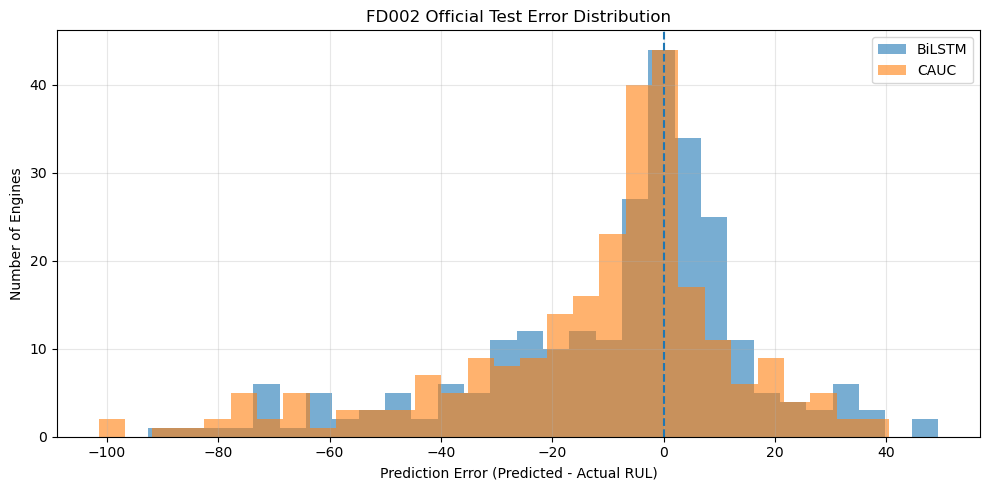

In [61]:
# ============================================================
# STEP 52
# FD002 ERROR DISTRIBUTION
# ============================================================

plt.figure(
    figsize=(10, 5)
)

plt.hist(
    fd002_error_analysis[
        "BiLSTM_Error"
    ],
    bins=30,
    alpha=0.6,
    label="BiLSTM"
)

plt.hist(
    fd002_error_analysis[
        "CAUC_Error"
    ],
    bins=30,
    alpha=0.6,
    label="CAUC"
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Prediction Error (Predicted - Actual RUL)"
)

plt.ylabel(
    "Number of Engines"
)

plt.title(
    "FD002 Official Test Error Distribution"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

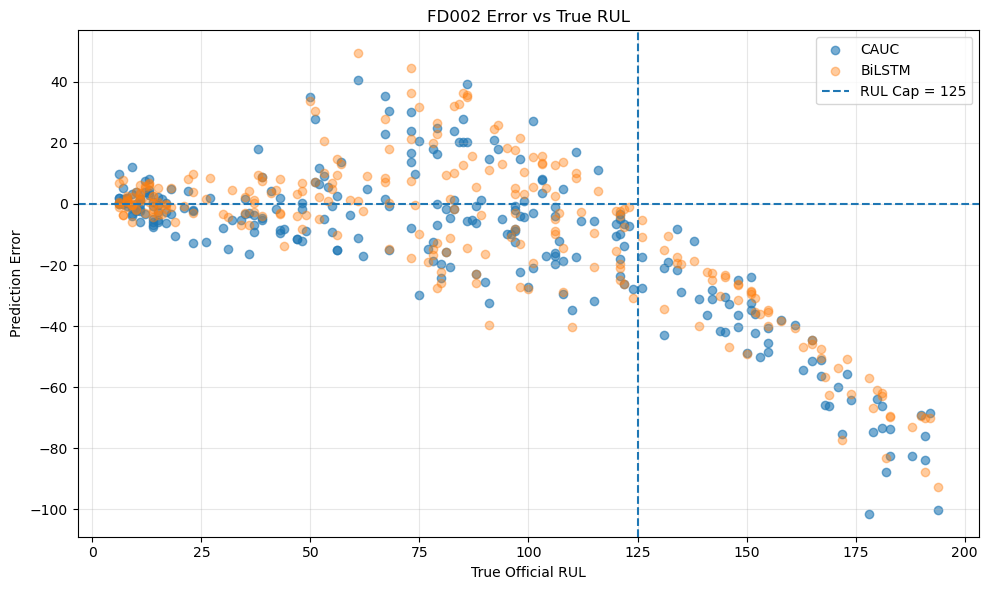

In [62]:
# ============================================================
# STEP 53
# ERROR VS TRUE RUL
# ============================================================

plt.figure(
    figsize=(10, 6)
)


plt.scatter(

    fd002_error_analysis[
        "True_RUL"
    ],

    fd002_error_analysis[
        "CAUC_Error"
    ],

    alpha=0.6,

    label="CAUC"
)


plt.scatter(

    fd002_error_analysis[
        "True_RUL"
    ],

    fd002_error_analysis[
        "BiLSTM_Error"
    ],

    alpha=0.4,

    label="BiLSTM"
)


plt.axhline(
    0,
    linestyle="--"
)


plt.axvline(
    125,
    linestyle="--",
    label="RUL Cap = 125"
)


plt.xlabel(
    "True Official RUL"
)

plt.ylabel(
    "Prediction Error"
)

plt.title(
    "FD002 Error vs True RUL"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [64]:
# ============================================================
# STEP 54 - FIXED
# FIND AVAILABLE FD002 VALIDATION PREDICTIONS
# ============================================================

print("=" * 70)
print("FD002 VALIDATION PREDICTION VARIABLES")
print("=" * 70)

# Take a stable snapshot first
globals_snapshot = list(globals().items())

for name, obj in globals_snapshot:

    name_lower = name.lower()

    if (
        "pred" in name_lower
        and "fd002" in name_lower
    ):

        try:

            if hasattr(obj, "shape"):

                print(
                    f"{name:<45} "
                    f"Shape: {obj.shape}"
                )

            else:

                print(
                    f"{name:<45} "
                    f"Type: {type(obj)}"
                )

        except Exception:

            pass

FD002 VALIDATION PREDICTION VARIABLES
pred_test_fd002                               Shape: (259,)
pred_bilstm_test_fd002                        Shape: (259,)


In [65]:
# ============================================================
# STEP 55
# CHECK FD002 VALIDATION OBJECTS
# ============================================================

variables_to_check = [

    "X_val_seq_fd002_50",
    "y_val_seq_fd002_50",

    "X_val_fd002_seq",
    "y_val_fd002_seq",

    "X_val_seq_fd002",
    "y_val_seq_fd002",

    "cauc_fd002_final",
    "bilstm_fd002_final",

    "pred_fd002_bilstm",
    "pred_fd002_cauc",
    "pred_val_fd002",
    "pred_cauc_fd002"
]


print("=" * 70)
print("FD002 VALIDATION OBJECT CHECK")
print("=" * 70)


for name in variables_to_check:

    if name in globals():

        obj = globals()[name]

        if hasattr(obj, "shape"):

            print(
                f"✅ {name:<35} "
                f"Shape: {obj.shape}"
            )

        elif hasattr(obj, "count_params"):

            print(
                f"✅ {name:<35} "
                f"Parameters: {obj.count_params()}"
            )

        else:

            print(
                f"✅ {name:<35} "
                f"Type: {type(obj)}"
            )

    else:

        print(
            f"❌ {name}"
        )

FD002 VALIDATION OBJECT CHECK
❌ X_val_seq_fd002_50
❌ y_val_seq_fd002_50
❌ X_val_fd002_seq
❌ y_val_fd002_seq
❌ X_val_seq_fd002
❌ y_val_seq_fd002
❌ cauc_fd002_final
✅ bilstm_fd002_final                  Parameters: 84801
❌ pred_fd002_bilstm
❌ pred_fd002_cauc
❌ pred_val_fd002
❌ pred_cauc_fd002


In [66]:
# ============================================================
# STEP 56
# RESTORE FD002 VALIDATION DATA FROM SAVED CHECKPOINT
# ============================================================

fd002_val_model = (
    dl_checkpoint[
        "fd002_val_model"
    ].copy()
)


print(
    "FD002 Validation Data Shape:",
    fd002_val_model.shape
)

print(
    "Validation Engines:",
    fd002_val_model[
        "engine_id"
    ].nunique()
)

print(
    "RUL_capped Available:",
    "RUL_capped" in fd002_val_model.columns
)

print(
    "All Model Sensor Columns Available:",
    all(
        col in fd002_val_model.columns
        for col in model_sensor_cols
    )
)

FD002 Validation Data Shape: (10295, 66)
Validation Engines: 52
RUL_capped Available: True
All Model Sensor Columns Available: True


In [67]:
# ============================================================
# STEP 57
# RECREATE FD002 VALIDATION SEQUENCES
# ============================================================

def create_validation_sequences(
    df,
    feature_cols,
    sequence_length=50,
    target_col="RUL_capped"
):

    sequences = []
    targets = []
    metadata = []


    for engine_id, engine_data in (
        df.groupby(
            "engine_id",
            sort=True
        )
    ):

        engine_data = (
            engine_data
            .sort_values("cycle")
            .reset_index(drop=True)
        )


        features = (
            engine_data[
                feature_cols
            ]
            .to_numpy(
                dtype=np.float32
            )
        )


        targets_array = (
            engine_data[
                target_col
            ]
            .to_numpy(
                dtype=np.float32
            )
        )


        cycles = (
            engine_data[
                "cycle"
            ]
            .to_numpy()
        )


        # No padding for validation.
        # Use only complete 50-cycle windows.
        for end_idx in range(
            sequence_length - 1,
            len(engine_data)
        ):

            start_idx = (
                end_idx
                -
                sequence_length
                +
                1
            )


            sequences.append(
                features[
                    start_idx:end_idx + 1
                ]
            )


            targets.append(
                targets_array[
                    end_idx
                ]
            )


            metadata.append({

                "engine_id":
                    engine_id,

                "cycle":
                    cycles[end_idx]
            })


    return (

        np.asarray(
            sequences,
            dtype=np.float32
        ),

        np.asarray(
            targets,
            dtype=np.float32
        ),

        pd.DataFrame(
            metadata
        )
    )

In [68]:
# ============================================================
# CREATE FD002 VALIDATION SEQUENCES
# ============================================================

(
    X_val_fd002_recreated,
    y_val_fd002_recreated,
    meta_val_fd002_recreated

) = create_validation_sequences(

    fd002_val_model,

    feature_cols=
        model_sensor_cols,

    sequence_length=50,

    target_col=
        "RUL_capped"
)


print(
    "X Validation Shape:",
    X_val_fd002_recreated.shape
)

print(
    "y Validation Shape:",
    y_val_fd002_recreated.shape
)

print(
    "Metadata Shape:",
    meta_val_fd002_recreated.shape
)

X Validation Shape: (7747, 50, 16)
y Validation Shape: (7747,)
Metadata Shape: (7747, 2)


In [69]:
# ============================================================
# STEP 58
# VALIDATION SEQUENCE QUALITY CHECK
# ============================================================

print(
    "NaN:",
    np.isnan(
        X_val_fd002_recreated
    ).sum()
)

print(
    "Inf:",
    np.isinf(
        X_val_fd002_recreated
    ).sum()
)

print(
    "Target NaN:",
    np.isnan(
        y_val_fd002_recreated
    ).sum()
)


assert (
    X_val_fd002_recreated.shape[1:]
    ==
    (50, 16)
)

assert (
    np.isfinite(
        X_val_fd002_recreated
    ).all()
)

assert (
    np.isfinite(
        y_val_fd002_recreated
    ).all()
)


print(
    "\n✅ FD002 validation sequences ready."
)

NaN: 0
Inf: 0
Target NaN: 0

✅ FD002 validation sequences ready.


In [70]:
# ============================================================
# STEP 59
# ENSURE FINAL FD002 CAUC MODEL IS AVAILABLE
# ============================================================

if "final_cauc_fd002" not in globals():

    final_cauc_fd002 = (
        tf.keras.models.load_model(

            FD002_FINAL_MODEL_PATH,

            custom_objects={
                "TemporalSum":
                    TemporalSum
            },

            compile=False
        )
    )


print(
    "CAUC Parameters:",
    final_cauc_fd002.count_params()
)

print(
    "BiLSTM Parameters:",
    bilstm_fd002_final.count_params()
)

CAUC Parameters: 97378
BiLSTM Parameters: 84801


In [118]:
# ============================================================
# STEP 60A
# FIND AVAILABLE CAUC MODEL VARIABLES
# ============================================================

print("=" * 70)
print("AVAILABLE CAUC / AERORUL MODEL VARIABLES")
print("=" * 70)

found_models = []

for name, obj in list(globals().items()):

    name_lower = name.lower()

    if (
        "cauc" in name_lower
        or
        "aerorul" in name_lower
    ):

        if isinstance(obj, tf.keras.Model):

            found_models.append(name)

            print(
                f"{name:<40}",
                f"Parameters: {obj.count_params()}"
            )


if len(found_models) == 0:

    print(
        "\n❌ No CAUC Keras model currently exists in memory."
    )

else:

    print(
        "\nAvailable CAUC models:",
        found_models
    )

AVAILABLE CAUC / AERORUL MODEL VARIABLES
final_cauc_fd002                         Parameters: 97378
final_cauc_fd003                         Parameters: 97378
cauc_weighted_fd002                      Parameters: 97378
cauc_augmented_fd002                     Parameters: 97378
cauc_light_aug_fd002                     Parameters: 97378
FINAL_FD002_CAUC_MODEL                   Parameters: 97378

Available CAUC models: ['final_cauc_fd002', 'final_cauc_fd003', 'cauc_weighted_fd002', 'cauc_augmented_fd002', 'cauc_light_aug_fd002', 'FINAL_FD002_CAUC_MODEL']


In [119]:
# ============================================================
# STEP 60 - CORRECTED
# FD002 VALIDATION PREDICTIONS
# BiLSTM vs FINAL SELECTED CAUC-AeroRULNet
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


# ------------------------------------------------------------
# 1. BiLSTM validation predictions
# ------------------------------------------------------------

pred_val_fd002_bilstm = (
    bilstm_fd002_final.predict(
        X_val_fd002_recreated,
        batch_size=256,
        verbose=0
    )
    .reshape(-1)
)


# ------------------------------------------------------------
# 2. FINAL ORIGINAL CAUC validation predictions
# ------------------------------------------------------------

pred_val_fd002_cauc = (
    final_cauc_fd002.predict(
        X_val_fd002_recreated,
        batch_size=256,
        verbose=0
    )
    .reshape(-1)
)


# ------------------------------------------------------------
# 3. Basic checks
# ------------------------------------------------------------

y_val_fd002_check = np.asarray(
    y_val_fd002_recreated
).reshape(-1)


print("=" * 70)
print("FD002 VALIDATION PREDICTIONS")
print("=" * 70)

print(
    "Targets:",
    y_val_fd002_check.shape
)

print(
    "BiLSTM Predictions:",
    pred_val_fd002_bilstm.shape
)

print(
    "CAUC Predictions:",
    pred_val_fd002_cauc.shape
)


assert (
    len(y_val_fd002_check)
    ==
    len(pred_val_fd002_bilstm)
    ==
    len(pred_val_fd002_cauc)
)


assert np.isfinite(
    pred_val_fd002_bilstm
).all()


assert np.isfinite(
    pred_val_fd002_cauc
).all()


print(
    "\n✅ Prediction shapes and values are valid."
)

FD002 VALIDATION PREDICTIONS
Targets: (7747,)
BiLSTM Predictions: (7747,)
CAUC Predictions: (7747,)

✅ Prediction shapes and values are valid.


In [120]:
# ============================================================
# STEP 60B
# VERIFY FINAL FD002 CAUC IDENTITY
# ============================================================

bilstm_verify_mae = mean_absolute_error(
    y_val_fd002_check,
    pred_val_fd002_bilstm
)

bilstm_verify_rmse = np.sqrt(
    mean_squared_error(
        y_val_fd002_check,
        pred_val_fd002_bilstm
    )
)

bilstm_verify_r2 = r2_score(
    y_val_fd002_check,
    pred_val_fd002_bilstm
)


cauc_verify_mae = mean_absolute_error(
    y_val_fd002_check,
    pred_val_fd002_cauc
)

cauc_verify_rmse = np.sqrt(
    mean_squared_error(
        y_val_fd002_check,
        pred_val_fd002_cauc
    )
)

cauc_verify_r2 = r2_score(
    y_val_fd002_check,
    pred_val_fd002_cauc
)


print("=" * 70)
print("FINAL MODEL IDENTITY VERIFICATION")
print("=" * 70)

print("\nBiLSTM")
print(f"MAE  : {bilstm_verify_mae:.6f}")
print(f"RMSE : {bilstm_verify_rmse:.6f}")
print(f"R²   : {bilstm_verify_r2:.6f}")


print("\nCAUC-AeroRULNet")
print(f"MAE  : {cauc_verify_mae:.6f}")
print(f"RMSE : {cauc_verify_rmse:.6f}")
print(f"R²   : {cauc_verify_r2:.6f}")


print("\nExpected FINAL CAUC:")
print("MAE  ≈ 10.469964")
print("RMSE ≈ 13.462717")
print("R²   ≈ 0.891859")

FINAL MODEL IDENTITY VERIFICATION

BiLSTM
MAE  : 9.973058
RMSE : 14.169504
R²   : 0.880206

CAUC-AeroRULNet
MAE  : 10.469964
RMSE : 13.462717
R²   : 0.891859

Expected FINAL CAUC:
MAE  ≈ 10.469964
RMSE ≈ 13.462717
R²   ≈ 0.891859


In [121]:
# ============================================================
# STEP 61
# FD002 OVERALL VALIDATION COMPARISON
# BiLSTM vs FINAL CAUC-AeroRULNet
# ============================================================

def calculate_regression_metrics(
    y_true,
    y_pred
):

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    mse = mean_squared_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_true,
        y_pred
    )

    bias = np.mean(
        y_pred - y_true
    )

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,
        "Bias": bias
    }


# ------------------------------------------------------------
# BiLSTM metrics
# ------------------------------------------------------------

bilstm_val_metrics = calculate_regression_metrics(

    y_val_fd002_check,

    pred_val_fd002_bilstm
)


# ------------------------------------------------------------
# CAUC metrics
# ------------------------------------------------------------

cauc_val_metrics = calculate_regression_metrics(

    y_val_fd002_check,

    pred_val_fd002_cauc
)


# ------------------------------------------------------------
# Comparison table
# ------------------------------------------------------------

overall_validation_comparison = pd.DataFrame([

    {
        "Model": "BiLSTM",
        **bilstm_val_metrics
    },

    {
        "Model": "CAUC-AeroRULNet",
        **cauc_val_metrics
    }

])


print("=" * 70)
print("FD002 VALIDATION MODEL COMPARISON")
print("=" * 70)

display(
    overall_validation_comparison
)

FD002 VALIDATION MODEL COMPARISON


,Model,MAE,MSE,RMSE,R2,Bias
0,BiLSTM,9.973058,200.774841,14.169504,0.880206,1.051381
1,CAUC-AeroRULNet,10.469964,181.244736,13.462717,0.891859,-1.856454


In [122]:
# ============================================================
# STEP 62
# CREATE FD002 RUL-RANGE VALIDATION DATA
# ============================================================

fd002_val_analysis = pd.DataFrame({

    "True_RUL":
        np.asarray(
            y_val_fd002_check
        ).reshape(-1),

    "BiLSTM_Pred":
        pred_val_fd002_bilstm,

    "CAUC_Pred":
        pred_val_fd002_cauc
})


# ------------------------------------------------------------
# Prediction errors
# Error = Prediction - Actual
# ------------------------------------------------------------

fd002_val_analysis[
    "BiLSTM_Error"
] = (

    fd002_val_analysis[
        "BiLSTM_Pred"
    ]

    -

    fd002_val_analysis[
        "True_RUL"
    ]
)


fd002_val_analysis[
    "CAUC_Error"
] = (

    fd002_val_analysis[
        "CAUC_Pred"
    ]

    -

    fd002_val_analysis[
        "True_RUL"
    ]
)


# ------------------------------------------------------------
# Absolute errors
# ------------------------------------------------------------

fd002_val_analysis[
    "BiLSTM_Abs_Error"
] = np.abs(

    fd002_val_analysis[
        "BiLSTM_Error"
    ]
)


fd002_val_analysis[
    "CAUC_Abs_Error"
] = np.abs(

    fd002_val_analysis[
        "CAUC_Error"
    ]
)


# ------------------------------------------------------------
# Assign RUL ranges
# ------------------------------------------------------------

fd002_val_analysis[
    "RUL_Range"
] = pd.cut(

    fd002_val_analysis[
        "True_RUL"
    ],

    bins=[
        -np.inf,
        30,
        60,
        90,
        125
    ],

    labels=[
        "0-30",
        "31-60",
        "61-90",
        "91-125"
    ]
)


# ------------------------------------------------------------
# Check distribution
# ------------------------------------------------------------

print("=" * 70)
print("FD002 VALIDATION RUL DISTRIBUTION")
print("=" * 70)


rul_distribution = (

    fd002_val_analysis[
        "RUL_Range"
    ]

    .value_counts(
        sort=False
    )
)


display(
    rul_distribution
)


print(
    "\nTotal Samples:",
    len(
        fd002_val_analysis
    )
)

FD002 VALIDATION RUL DISTRIBUTION


RUL_Range
0-30      1612
31-60     1560
61-90     1545
91-125    3030
Name: count, dtype: int64


Total Samples: 7747


In [123]:
# ============================================================
# STEP 63
# FD002 RUL-RANGE PERFORMANCE COMPARISON
# ============================================================

range_results = []


range_order = [
    "0-30",
    "31-60",
    "61-90",
    "91-125"
]


for rul_range in range_order:

    # --------------------------------------------------------
    # Select samples belonging to current RUL range
    # --------------------------------------------------------

    group = fd002_val_analysis[

        fd002_val_analysis[
            "RUL_Range"
        ]

        ==

        rul_range
    ]


    y_true_group = (
        group[
            "True_RUL"
        ]
        .values
    )


    bilstm_pred_group = (
        group[
            "BiLSTM_Pred"
        ]
        .values
    )


    cauc_pred_group = (
        group[
            "CAUC_Pred"
        ]
        .values
    )


    # --------------------------------------------------------
    # MAE
    # --------------------------------------------------------

    bilstm_mae = mean_absolute_error(
        y_true_group,
        bilstm_pred_group
    )


    cauc_mae = mean_absolute_error(
        y_true_group,
        cauc_pred_group
    )


    # --------------------------------------------------------
    # RMSE
    # --------------------------------------------------------

    bilstm_rmse = np.sqrt(

        mean_squared_error(
            y_true_group,
            bilstm_pred_group
        )
    )


    cauc_rmse = np.sqrt(

        mean_squared_error(
            y_true_group,
            cauc_pred_group
        )
    )


    # --------------------------------------------------------
    # Bias
    # Positive = overprediction
    # Negative = underprediction
    # --------------------------------------------------------

    bilstm_bias = np.mean(

        bilstm_pred_group
        -
        y_true_group
    )


    cauc_bias = np.mean(

        cauc_pred_group
        -
        y_true_group
    )


    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    range_results.append({

        "RUL_Range":
            rul_range,

        "Samples":
            len(group),

        "BiLSTM_MAE":
            bilstm_mae,

        "CAUC_MAE":
            cauc_mae,

        "BiLSTM_RMSE":
            bilstm_rmse,

        "CAUC_RMSE":
            cauc_rmse,

        "BiLSTM_Bias":
            bilstm_bias,

        "CAUC_Bias":
            cauc_bias
    })


# ------------------------------------------------------------
# Final table
# ------------------------------------------------------------

fd002_rul_range_comparison = pd.DataFrame(
    range_results
)


print("=" * 70)
print("FD002 RUL-RANGE PERFORMANCE COMPARISON")
print("=" * 70)


display(
    fd002_rul_range_comparison
)

FD002 RUL-RANGE PERFORMANCE COMPARISON


,RUL_Range,Samples,BiLSTM_MAE,CAUC_MAE,BiLSTM_RMSE,CAUC_RMSE,BiLSTM_Bias,CAUC_Bias
0,0-30,1612,3.359543,3.862302,4.586803,5.161344,1.737290,0.531415
1,31-60,1560,9.299115,9.897471,12.665732,12.568773,5.450319,2.000364
2,61-90,1545,15.726214,13.784912,19.756419,16.826314,7.933249,5.386116
3,91-125,3030,10.904975,12.589782,14.850115,14.950885,-5.087403,-8.805515


In [124]:
# ============================================================
# STEP 64
# LOCK FINAL CAUC-AeroRULNet MODELS
# ============================================================

FINAL_CAUC_FD002 = final_cauc_fd002
FINAL_CAUC_FD003 = final_cauc_fd003


print("=" * 70)
print("FINAL CAUC-AeroRULNet MODELS LOCKED")
print("=" * 70)

print(
    "FD002 Parameters:",
    FINAL_CAUC_FD002.count_params()
)

print(
    "FD003 Parameters:",
    FINAL_CAUC_FD003.count_params()
)


assert FINAL_CAUC_FD002.count_params() == 97378
assert FINAL_CAUC_FD003.count_params() == 97378


print("\n✅ FD002 final model locked.")
print("✅ FD003 final model locked.")

FINAL CAUC-AeroRULNet MODELS LOCKED
FD002 Parameters: 97378
FD003 Parameters: 97378

✅ FD002 final model locked.
✅ FD003 final model locked.


In [125]:
# ============================================================
# STEP 65
# FINAL CAUC-AeroRULNet CONFIGURATION
# ============================================================

FINAL_CAUC_CONFIG = {

    "Model":
        "CAUC-AeroRULNet",

    "Sequence_Length":
        50,

    "Number_of_Sensors":
        16,

    "Learning_Rate":
        0.0005,

    "FD002_Dropout":
        0.20,

    "FD003_Dropout":
        0.20,

    "Loss":
        "MSE",

    "Parameters":
        97378,

    "Sensors": [
        "sensor_2",
        "sensor_3",
        "sensor_4",
        "sensor_6",
        "sensor_7",
        "sensor_8",
        "sensor_9",
        "sensor_10",
        "sensor_11",
        "sensor_12",
        "sensor_13",
        "sensor_14",
        "sensor_15",
        "sensor_17",
        "sensor_20",
        "sensor_21"
    ]
}


print("=" * 70)
print("FINAL CAUC CONFIGURATION")
print("=" * 70)

for key, value in FINAL_CAUC_CONFIG.items():

    print(
        f"{key}: {value}"
    )

FINAL CAUC CONFIGURATION
Model: CAUC-AeroRULNet
Sequence_Length: 50
Number_of_Sensors: 16
Learning_Rate: 0.0005
FD002_Dropout: 0.2
FD003_Dropout: 0.2
Loss: MSE
Parameters: 97378
Sensors: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


In [126]:
# ============================================================
# STEP 66
# FINAL VALIDATION RESULTS
# ============================================================

final_validation_results = pd.DataFrame([

    {
        "Dataset": "FD002",
        "Model": "BiLSTM",
        "MAE": 9.973058,
        "RMSE": 14.169504,
        "R2": 0.880206
    },

    {
        "Dataset": "FD002",
        "Model": "CAUC-AeroRULNet",
        "MAE": 10.469964,
        "RMSE": 13.462717,
        "R2": 0.891859
    },

    {
        "Dataset": "FD003",
        "Model": "BiLSTM",
        "MAE": 8.270232,
        "RMSE": 11.366003,
        "R2": 0.926313
    },

    {
        "Dataset": "FD003",
        "Model": "CAUC-AeroRULNet",
        "MAE": 8.556795,
        "RMSE": 11.314010,
        "R2": 0.926985
    }

])


print("=" * 70)
print("FINAL VALIDATION RESULTS")
print("=" * 70)

display(
    final_validation_results
)

FINAL VALIDATION RESULTS


,Dataset,Model,MAE,RMSE,R2
0,FD002,BiLSTM,9.973058,14.169504,0.880206
1,FD002,CAUC-AeroRULNet,10.469964,13.462717,0.891859
2,FD003,BiLSTM,8.270232,11.366003,0.926313
3,FD003,CAUC-AeroRULNet,8.556795,11.314010,0.926985


In [127]:
# ============================================================
# STEP 67
# CAUC IMPROVEMENT OVER BiLSTM
# ============================================================

fd002_improvement = (
    (
        14.169504
        -
        13.462717
    )
    /
    14.169504
) * 100


fd003_improvement = (
    (
        11.366003
        -
        11.314010
    )
    /
    11.366003
) * 100


final_improvement_results = pd.DataFrame({

    "Dataset": [
        "FD002",
        "FD003"
    ],

    "BiLSTM_RMSE": [
        14.169504,
        11.366003
    ],

    "CAUC_RMSE": [
        13.462717,
        11.314010
    ],

    "Improvement_Percent": [
        fd002_improvement,
        fd003_improvement
    ]
})


display(
    final_improvement_results
)


print(
    f"\nFD002 RMSE Improvement: "
    f"{fd002_improvement:.2f}%"
)

print(
    f"FD003 RMSE Improvement: "
    f"{fd003_improvement:.2f}%"
)

,Dataset,BiLSTM_RMSE,CAUC_RMSE,Improvement_Percent
0,FD002,14.169504,13.462717,4.988086
1,FD003,11.366003,11.314010,0.457443



FD002 RMSE Improvement: 4.99%
FD003 RMSE Improvement: 0.46%


In [128]:
# ============================================================
# STEP 68
# FINAL MODEL / ARTIFACT DIRECTORIES
# ============================================================

import os
import joblib


PROJECT_DIR = r"D:\IST\Aircraft_Engine_RUL"

FINAL_MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models",
    "final"
)

FINAL_RESULT_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "final"
)


os.makedirs(
    FINAL_MODEL_DIR,
    exist_ok=True
)

os.makedirs(
    FINAL_RESULT_DIR,
    exist_ok=True
)


print(
    "Model Directory:",
    FINAL_MODEL_DIR
)

print(
    "Result Directory:",
    FINAL_RESULT_DIR
)

Model Directory: D:\IST\Aircraft_Engine_RUL\models\final
Result Directory: D:\IST\Aircraft_Engine_RUL\results\final


In [129]:
# ============================================================
# STEP 69
# SAVE FINAL CAUC MODELS
# ============================================================

FD002_FINAL_PATH = os.path.join(
    FINAL_MODEL_DIR,
    "CAUC_AeroRULNet_FD002.keras"
)

FD003_FINAL_PATH = os.path.join(
    FINAL_MODEL_DIR,
    "CAUC_AeroRULNet_FD003.keras"
)


FINAL_CAUC_FD002.save(
    FD002_FINAL_PATH
)

FINAL_CAUC_FD003.save(
    FD003_FINAL_PATH
)


print("=" * 70)
print("FINAL MODELS SAVED")
print("=" * 70)

print(
    "FD002:",
    FD002_FINAL_PATH
)

print(
    "FD003:",
    FD003_FINAL_PATH
)

FINAL MODELS SAVED
FD002: D:\IST\Aircraft_Engine_RUL\models\final\CAUC_AeroRULNet_FD002.keras
FD003: D:\IST\Aircraft_Engine_RUL\models\final\CAUC_AeroRULNet_FD003.keras


In [130]:
# ============================================================
# STEP 70
# SAVE FINAL RESULTS AND CONFIGURATION
# ============================================================

# Configuration
joblib.dump(

    FINAL_CAUC_CONFIG,

    os.path.join(
        FINAL_RESULT_DIR,
        "final_cauc_config.pkl"
    )
)


# Validation results
final_validation_results.to_csv(

    os.path.join(
        FINAL_RESULT_DIR,
        "final_validation_results.csv"
    ),

    index=False
)


# Improvement results
final_improvement_results.to_csv(

    os.path.join(
        FINAL_RESULT_DIR,
        "final_improvement_results.csv"
    ),

    index=False
)


# RUL range analysis
fd002_rul_range_comparison.to_csv(

    os.path.join(
        FINAL_RESULT_DIR,
        "fd002_rul_range_comparison.csv"
    ),

    index=False
)


print("=" * 70)
print("FINAL ARTIFACTS SAVED")
print("=" * 70)

print("✅ Configuration")
print("✅ Validation results")
print("✅ Improvement results")
print("✅ FD002 RUL-range analysis")

FINAL ARTIFACTS SAVED
✅ Configuration
✅ Validation results
✅ Improvement results
✅ FD002 RUL-range analysis


In [131]:
# ============================================================
# STEP 71
# FINAL SAVE VERIFICATION
# ============================================================

files_to_verify = {

    "FD002 Model":
        FD002_FINAL_PATH,

    "FD003 Model":
        FD003_FINAL_PATH,

    "Configuration":
        os.path.join(
            FINAL_RESULT_DIR,
            "final_cauc_config.pkl"
        ),

    "Validation Results":
        os.path.join(
            FINAL_RESULT_DIR,
            "final_validation_results.csv"
        ),

    "Improvement Results":
        os.path.join(
            FINAL_RESULT_DIR,
            "final_improvement_results.csv"
        ),

    "RUL Range Results":
        os.path.join(
            FINAL_RESULT_DIR,
            "fd002_rul_range_comparison.csv"
        )
}


print("=" * 70)
print("FINAL PROJECT ARTIFACT VERIFICATION")
print("=" * 70)


all_files_exist = True


for name, path in files_to_verify.items():

    exists = os.path.exists(path)

    print(
        f"{'✅' if exists else '❌'} "
        f"{name}"
    )

    if not exists:
        all_files_exist = False


if all_files_exist:

    print(
        "\n🎉 ALL FINAL MODEL ARTIFACTS SUCCESSFULLY SAVED."
    )

else:

    print(
        "\n❌ Some artifacts are missing."
    )

FINAL PROJECT ARTIFACT VERIFICATION
✅ FD002 Model
✅ FD003 Model
✅ Configuration
✅ Validation Results
✅ Improvement Results
✅ RUL Range Results

🎉 ALL FINAL MODEL ARTIFACTS SUCCESSFULLY SAVED.


In [132]:
# ============================================================
# STEP 72
# MAINTENANCE RISK CLASSIFICATION FUNCTION
# ============================================================

def classify_maintenance_risk(rul):
    """
    Convert predicted Remaining Useful Life (RUL)
    into an operational maintenance risk category.
    """

    if rul <= 30:

        return "Critical"

    elif rul <= 60:

        return "High Risk"

    elif rul <= 90:

        return "Moderate"

    else:

        return "Healthy"

In [133]:
# ============================================================
# MAINTENANCE RECOMMENDATION FUNCTION
# ============================================================

def maintenance_recommendation(risk_level):

    recommendations = {

        "Critical":
            "Immediate maintenance required",

        "High Risk":
            "Schedule maintenance soon",

        "Moderate":
            "Increase monitoring frequency",

        "Healthy":
            "Continue routine monitoring"
    }

    return recommendations[
        risk_level
    ]

In [134]:
# ============================================================
# STEP 73
# TEST MAINTENANCE DECISION LOGIC
# ============================================================

test_rul_values = [
    10,
    25,
    45,
    75,
    100,
    125
]


print("=" * 75)
print("MAINTENANCE DECISION SYSTEM TEST")
print("=" * 75)


for rul in test_rul_values:

    risk = classify_maintenance_risk(
        rul
    )

    recommendation = (
        maintenance_recommendation(
            risk
        )
    )

    print(
        f"RUL = {rul:3d} | "
        f"Risk = {risk:10s} | "
        f"{recommendation}"
    )

MAINTENANCE DECISION SYSTEM TEST
RUL =  10 | Risk = Critical   | Immediate maintenance required
RUL =  25 | Risk = Critical   | Immediate maintenance required
RUL =  45 | Risk = High Risk  | Schedule maintenance soon
RUL =  75 | Risk = Moderate   | Increase monitoring frequency
RUL = 100 | Risk = Healthy    | Continue routine monitoring
RUL = 125 | Risk = Healthy    | Continue routine monitoring


In [135]:
# ============================================================
# STEP 74
# FD002 VALIDATION MAINTENANCE DECISION DATASET
# ============================================================

fd002_decision_results = pd.DataFrame({

    "True_RUL":
        y_val_fd002_check,

    "Predicted_RUL":
        pred_val_fd002_cauc
})


# ------------------------------------------------------------
# True maintenance class
# ------------------------------------------------------------

fd002_decision_results[
    "True_Risk"
] = (

    fd002_decision_results[
        "True_RUL"
    ]

    .apply(
        classify_maintenance_risk
    )
)


# ------------------------------------------------------------
# Predicted maintenance class
# ------------------------------------------------------------

fd002_decision_results[
    "Predicted_Risk"
] = (

    fd002_decision_results[
        "Predicted_RUL"
    ]

    .apply(
        classify_maintenance_risk
    )
)


# ------------------------------------------------------------
# Maintenance recommendation
# ------------------------------------------------------------

fd002_decision_results[
    "Recommendation"
] = (

    fd002_decision_results[
        "Predicted_Risk"
    ]

    .apply(
        maintenance_recommendation
    )
)


print("=" * 75)
print("FD002 MAINTENANCE DECISION RESULTS")
print("=" * 75)


display(
    fd002_decision_results.head(20)
)

FD002 MAINTENANCE DECISION RESULTS


,True_RUL,Predicted_RUL,True_Risk,Predicted_Risk,Recommendation
0,124.0,110.566170,Healthy,Healthy,Continue routine monitoring
1,123.0,114.931625,Healthy,Healthy,Continue routine monitoring
2,122.0,114.016121,Healthy,Healthy,Continue routine monitoring
3,121.0,116.494667,Healthy,Healthy,Continue routine monitoring
4,120.0,117.363312,Healthy,Healthy,Continue routine monitoring
5,119.0,117.346085,Healthy,Healthy,Continue routine monitoring
6,118.0,112.866501,Healthy,Healthy,Continue routine monitoring
7,117.0,110.608109,Healthy,Healthy,Continue routine monitoring
8,116.0,111.997284,Healthy,Healthy,Continue routine monitoring
9,115.0,115.342079,Healthy,Healthy,Continue routine monitoring


In [136]:
# ============================================================
# STEP 75
# TRUE VS PREDICTED RISK DISTRIBUTION
# ============================================================

risk_order = [
    "Critical",
    "High Risk",
    "Moderate",
    "Healthy"
]


true_distribution = (

    fd002_decision_results[
        "True_Risk"
    ]

    .value_counts()

    .reindex(
        risk_order,
        fill_value=0
    )
)


predicted_distribution = (

    fd002_decision_results[
        "Predicted_Risk"
    ]

    .value_counts()

    .reindex(
        risk_order,
        fill_value=0
    )
)


risk_distribution_df = pd.DataFrame({

    "True_Count":
        true_distribution,

    "Predicted_Count":
        predicted_distribution
})


print("=" * 70)
print("FD002 MAINTENANCE RISK DISTRIBUTION")
print("=" * 70)


display(
    risk_distribution_df
)

FD002 MAINTENANCE RISK DISTRIBUTION


,True_Count,Predicted_Count
Critical,1612,1715
High Risk,1560,1342
Moderate,1545,1369
Healthy,3030,3321


In [137]:
# ============================================================
# STEP 76
# MAINTENANCE DECISION CLASSIFICATION METRICS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)


y_true_risk = (
    fd002_decision_results[
        "True_Risk"
    ]
)


y_pred_risk = (
    fd002_decision_results[
        "Predicted_Risk"
    ]
)


# ------------------------------------------------------------
# Overall accuracy
# ------------------------------------------------------------

decision_accuracy = accuracy_score(
    y_true_risk,
    y_pred_risk
)


# ------------------------------------------------------------
# Macro metrics
# ------------------------------------------------------------

decision_precision = precision_score(

    y_true_risk,
    y_pred_risk,

    labels=risk_order,

    average="macro",

    zero_division=0
)


decision_recall = recall_score(

    y_true_risk,
    y_pred_risk,

    labels=risk_order,

    average="macro",

    zero_division=0
)


decision_f1 = f1_score(

    y_true_risk,
    y_pred_risk,

    labels=risk_order,

    average="macro",

    zero_division=0
)


print("=" * 70)
print("FD002 MAINTENANCE DECISION PERFORMANCE")
print("=" * 70)

print(
    f"Accuracy  : {decision_accuracy:.4f}"
)

print(
    f"Precision : {decision_precision:.4f}"
)

print(
    f"Recall    : {decision_recall:.4f}"
)

print(
    f"F1 Score  : {decision_f1:.4f}"
)

FD002 MAINTENANCE DECISION PERFORMANCE
Accuracy  : 0.7808
Precision : 0.7541
Recall    : 0.7462
F1 Score  : 0.7480


In [138]:
# ============================================================
# STEP 77
# DETAILED MAINTENANCE CLASSIFICATION REPORT
# ============================================================

report = classification_report(

    y_true_risk,

    y_pred_risk,

    labels=risk_order,

    target_names=risk_order,

    zero_division=0,

    output_dict=True
)


classification_report_df = (

    pd.DataFrame(
        report
    )

    .transpose()
)


print("=" * 70)
print("FD002 MAINTENANCE CLASSIFICATION REPORT")
print("=" * 70)


display(
    classification_report_df
)

FD002 MAINTENANCE CLASSIFICATION REPORT


,precision,recall,f1-score,support
Critical,0.871137,0.926799,0.898106,1612.000000
High Risk,0.734724,0.632051,0.679531,1560.000000
Moderate,0.571220,0.506149,0.536719,1545.000000
Healthy,0.839205,0.919802,0.877657,3030.000000
accuracy,0.780818,0.780818,0.780818,0.780818
macro avg,0.754072,0.746200,0.748004,7747.000000
weighted avg,0.771366,0.780818,0.774022,7747.000000


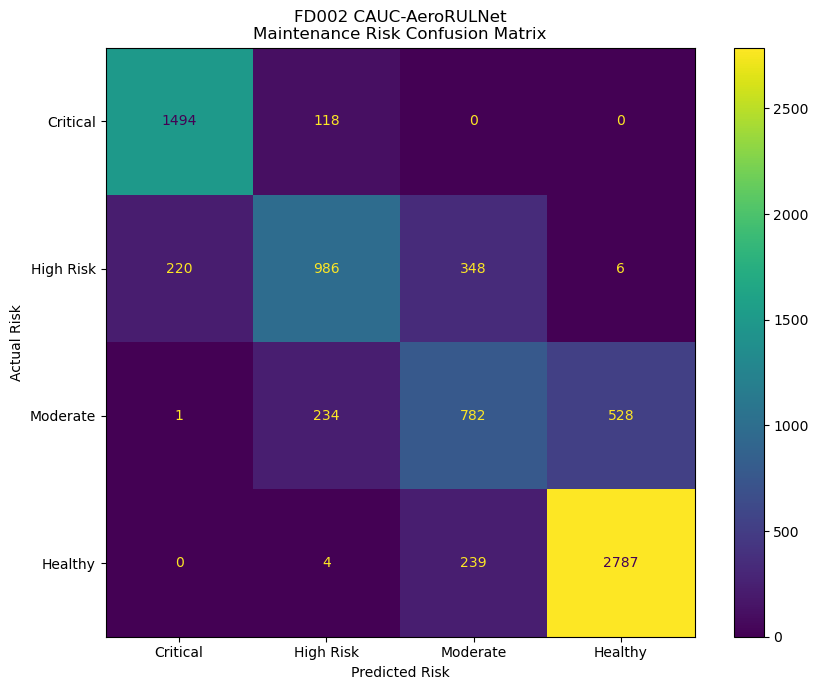

In [139]:
# ============================================================
# STEP 78
# MAINTENANCE DECISION CONFUSION MATRIX
# ============================================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)


cm = confusion_matrix(

    y_true_risk,

    y_pred_risk,

    labels=risk_order
)


disp = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=risk_order
)


fig, ax = plt.subplots(
    figsize=(9, 7)
)


disp.plot(
    ax=ax,
    values_format="d"
)


plt.title(
    "FD002 CAUC-AeroRULNet\nMaintenance Risk Confusion Matrix"
)

plt.xlabel(
    "Predicted Risk"
)

plt.ylabel(
    "Actual Risk"
)

plt.tight_layout()

plt.show()

In [140]:
# ============================================================
# STEP 79
# PREPARE FD003 VALIDATION DATA FOR DECISION SUPPORT
# ============================================================

# Restore FD003 validation dataframe
fd003_val_model = (
    dl_checkpoint[
        "fd003_val_model"
    ].copy()
)


# Recreate 50-cycle validation sequences
(
    X_val_fd003_recreated,
    y_val_fd003_recreated,
    meta_val_fd003_recreated

) = create_validation_sequences(

    fd003_val_model,

    feature_cols=model_sensor_cols,

    sequence_length=50,

    target_col="RUL_capped"
)


print(
    "FD003 Validation Sequences:",
    X_val_fd003_recreated.shape
)

print(
    "FD003 Targets:",
    y_val_fd003_recreated.shape
)

FD003 Validation Sequences: (3728, 50, 16)
FD003 Targets: (3728,)


In [141]:
# ============================================================
# STEP 80
# FD003 FINAL CAUC VALIDATION PREDICTIONS
# ============================================================

pred_val_fd003_cauc = (

    FINAL_CAUC_FD003.predict(

        X_val_fd003_recreated,

        batch_size=256,

        verbose=0

    ).reshape(-1)
)


print(
    "Predictions:",
    pred_val_fd003_cauc.shape
)


assert (
    len(pred_val_fd003_cauc)
    ==
    len(y_val_fd003_recreated)
)


print(
    "✅ FD003 predictions ready."
)

Predictions: (3728,)
✅ FD003 predictions ready.


In [142]:
# ============================================================
# STEP 81
# VERIFY FINAL FD003 CAUC PERFORMANCE
# ============================================================

fd003_verify_mae = mean_absolute_error(
    y_val_fd003_recreated,
    pred_val_fd003_cauc
)

fd003_verify_rmse = np.sqrt(
    mean_squared_error(
        y_val_fd003_recreated,
        pred_val_fd003_cauc
    )
)

fd003_verify_r2 = r2_score(
    y_val_fd003_recreated,
    pred_val_fd003_cauc
)


print("=" * 65)
print("FD003 FINAL CAUC VERIFICATION")
print("=" * 65)

print(
    f"MAE  : {fd003_verify_mae:.6f}"
)

print(
    f"RMSE : {fd003_verify_rmse:.6f}"
)

print(
    f"R²   : {fd003_verify_r2:.6f}"
)

FD003 FINAL CAUC VERIFICATION
MAE  : 8.556795
RMSE : 11.314010
R²   : 0.926985


In [143]:
# ============================================================
# STEP 82
# FD003 MAINTENANCE DECISION DATASET
# ============================================================

fd003_decision_results = pd.DataFrame({

    "True_RUL":
        y_val_fd003_recreated,

    "Predicted_RUL":
        pred_val_fd003_cauc
})


fd003_decision_results[
    "True_Risk"
] = (

    fd003_decision_results[
        "True_RUL"
    ]

    .apply(
        classify_maintenance_risk
    )
)


fd003_decision_results[
    "Predicted_Risk"
] = (

    fd003_decision_results[
        "Predicted_RUL"
    ]

    .apply(
        classify_maintenance_risk
    )
)


fd003_decision_results[
    "Recommendation"
] = (

    fd003_decision_results[
        "Predicted_Risk"
    ]

    .apply(
        maintenance_recommendation
    )
)


display(
    fd003_decision_results.head(15)
)

,True_RUL,Predicted_RUL,True_Risk,Predicted_Risk,Recommendation
0,125.0,119.234871,Healthy,Healthy,Continue routine monitoring
1,125.0,120.077759,Healthy,Healthy,Continue routine monitoring
2,125.0,122.554863,Healthy,Healthy,Continue routine monitoring
3,125.0,123.551216,Healthy,Healthy,Continue routine monitoring
4,125.0,120.902176,Healthy,Healthy,Continue routine monitoring
5,125.0,121.084030,Healthy,Healthy,Continue routine monitoring
6,125.0,123.323326,Healthy,Healthy,Continue routine monitoring
7,125.0,121.243942,Healthy,Healthy,Continue routine monitoring
8,125.0,119.232185,Healthy,Healthy,Continue routine monitoring
9,125.0,120.863487,Healthy,Healthy,Continue routine monitoring


In [144]:
# ============================================================
# STEP 83
# FD003 TRUE VS PREDICTED RISK DISTRIBUTION
# ============================================================

fd003_true_distribution = (

    fd003_decision_results[
        "True_Risk"
    ]

    .value_counts()

    .reindex(
        risk_order,
        fill_value=0
    )
)


fd003_pred_distribution = (

    fd003_decision_results[
        "Predicted_Risk"
    ]

    .value_counts()

    .reindex(
        risk_order,
        fill_value=0
    )
)


fd003_risk_distribution = pd.DataFrame({

    "True_Count":
        fd003_true_distribution,

    "Predicted_Count":
        fd003_pred_distribution
})


display(
    fd003_risk_distribution
)

,True_Count,Predicted_Count
Critical,620,653
High Risk,600,544
Moderate,600,560
Healthy,1908,1971


In [145]:
# ============================================================
# STEP 84
# FD003 MAINTENANCE DECISION PERFORMANCE
# ============================================================

y_true_risk_fd003 = (
    fd003_decision_results[
        "True_Risk"
    ]
)

y_pred_risk_fd003 = (
    fd003_decision_results[
        "Predicted_Risk"
    ]
)


fd003_accuracy = accuracy_score(
    y_true_risk_fd003,
    y_pred_risk_fd003
)


fd003_precision = precision_score(

    y_true_risk_fd003,
    y_pred_risk_fd003,

    labels=risk_order,

    average="macro",

    zero_division=0
)


fd003_recall = recall_score(

    y_true_risk_fd003,
    y_pred_risk_fd003,

    labels=risk_order,

    average="macro",

    zero_division=0
)


fd003_f1 = f1_score(

    y_true_risk_fd003,
    y_pred_risk_fd003,

    labels=risk_order,

    average="macro",

    zero_division=0
)


print("=" * 70)
print("FD003 MAINTENANCE DECISION PERFORMANCE")
print("=" * 70)

print(
    f"Accuracy  : {fd003_accuracy:.4f}"
)

print(
    f"Precision : {fd003_precision:.4f}"
)

print(
    f"Recall    : {fd003_recall:.4f}"
)

print(
    f"F1 Score  : {fd003_f1:.4f}"
)

FD003 MAINTENANCE DECISION PERFORMANCE
Accuracy  : 0.8452
Precision : 0.8072
Recall    : 0.7968
F1 Score  : 0.8012


In [146]:
# ============================================================
# STEP 85
# FD003 CLASSIFICATION REPORT
# ============================================================

fd003_report = classification_report(

    y_true_risk_fd003,

    y_pred_risk_fd003,

    labels=risk_order,

    target_names=risk_order,

    zero_division=0,

    output_dict=True
)


fd003_report_df = (

    pd.DataFrame(
        fd003_report
    )
    .transpose()
)


display(
    fd003_report_df
)

,precision,recall,f1-score,support
Critical,0.875957,0.922581,0.898665,620.000000
High Risk,0.810662,0.735000,0.770979,600.000000
Moderate,0.639286,0.596667,0.617241,600.000000
Healthy,0.903095,0.932914,0.917762,1908.000000
accuracy,0.845225,0.845225,0.845225,0.845225
macro avg,0.807250,0.796790,0.801162,3728.000000
weighted avg,0.841246,0.845225,0.842595,3728.000000


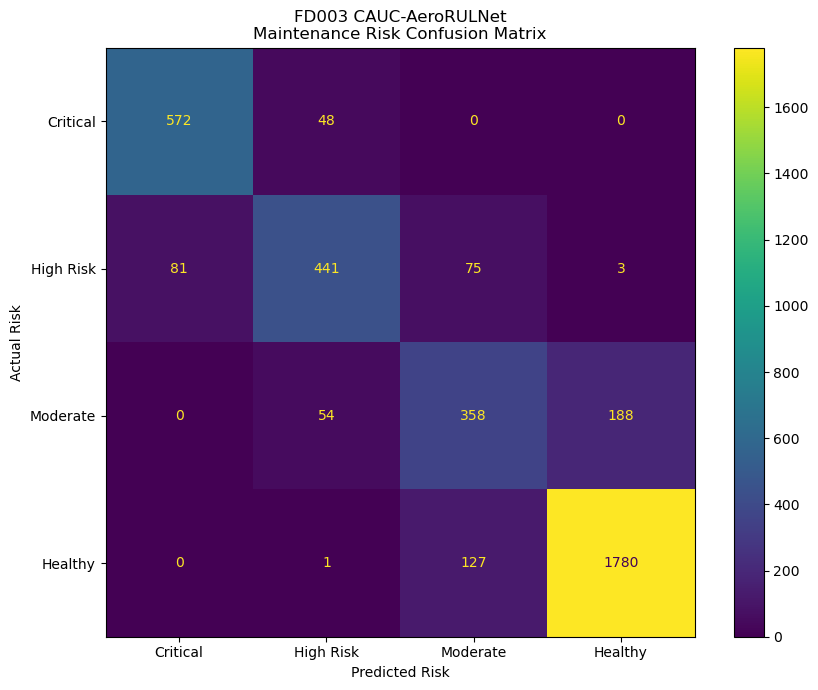

In [147]:
# ============================================================
# STEP 86
# FD003 MAINTENANCE RISK CONFUSION MATRIX
# ============================================================

cm_fd003 = confusion_matrix(

    y_true_risk_fd003,

    y_pred_risk_fd003,

    labels=risk_order
)


disp_fd003 = ConfusionMatrixDisplay(

    confusion_matrix=
        cm_fd003,

    display_labels=
        risk_order
)


fig, ax = plt.subplots(
    figsize=(9, 7)
)


disp_fd003.plot(
    ax=ax,
    values_format="d"
)


plt.title(
    "FD003 CAUC-AeroRULNet\n"
    "Maintenance Risk Confusion Matrix"
)

plt.xlabel(
    "Predicted Risk"
)

plt.ylabel(
    "Actual Risk"
)

plt.tight_layout()

plt.show()

In [148]:
# ============================================================
# STEP 87
# FINAL MAINTENANCE DECISION COMPARISON
# ============================================================

final_decision_comparison = pd.DataFrame([

    {
        "Dataset": "FD002",

        "Accuracy":
            decision_accuracy,

        "Macro_Precision":
            decision_precision,

        "Macro_Recall":
            decision_recall,

        "Macro_F1":
            decision_f1,

        "Critical_Recall":
            classification_report_df
            .loc[
                "Critical",
                "recall"
            ],

        "Critical_F1":
            classification_report_df
            .loc[
                "Critical",
                "f1-score"
            ]
    },


    {
        "Dataset": "FD003",

        "Accuracy":
            fd003_accuracy,

        "Macro_Precision":
            fd003_precision,

        "Macro_Recall":
            fd003_recall,

        "Macro_F1":
            fd003_f1,

        "Critical_Recall":
            fd003_report_df
            .loc[
                "Critical",
                "recall"
            ],

        "Critical_F1":
            fd003_report_df
            .loc[
                "Critical",
                "f1-score"
            ]
    }

])


print("=" * 75)
print("FINAL MAINTENANCE DECISION PERFORMANCE")
print("=" * 75)


display(
    final_decision_comparison
)

FINAL MAINTENANCE DECISION PERFORMANCE


,Dataset,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Critical_Recall,Critical_F1
0,FD002,0.780818,0.754072,0.74620,0.748004,0.926799,0.898106
1,FD003,0.845225,0.807250,0.79679,0.801162,0.922581,0.898665


In [149]:
# ============================================================
# STEP 88
# FINAL FD002 vs FD003 MAINTENANCE DECISION COMPARISON
# ============================================================

final_decision_comparison = pd.DataFrame([

    {
        "Dataset": "FD002",

        "Accuracy":
            decision_accuracy,

        "Macro_Precision":
            decision_precision,

        "Macro_Recall":
            decision_recall,

        "Macro_F1":
            decision_f1,

        "Critical_Precision":
            classification_report_df.loc[
                "Critical",
                "precision"
            ],

        "Critical_Recall":
            classification_report_df.loc[
                "Critical",
                "recall"
            ],

        "Critical_F1":
            classification_report_df.loc[
                "Critical",
                "f1-score"
            ],

        "Healthy_Recall":
            classification_report_df.loc[
                "Healthy",
                "recall"
            ]
    },

    {
        "Dataset": "FD003",

        "Accuracy":
            fd003_accuracy,

        "Macro_Precision":
            fd003_precision,

        "Macro_Recall":
            fd003_recall,

        "Macro_F1":
            fd003_f1,

        "Critical_Precision":
            fd003_report_df.loc[
                "Critical",
                "precision"
            ],

        "Critical_Recall":
            fd003_report_df.loc[
                "Critical",
                "recall"
            ],

        "Critical_F1":
            fd003_report_df.loc[
                "Critical",
                "f1-score"
            ],

        "Healthy_Recall":
            fd003_report_df.loc[
                "Healthy",
                "recall"
            ]
    }
])


print("=" * 80)
print("FINAL MAINTENANCE DECISION COMPARISON")
print("=" * 80)

display(
    final_decision_comparison.round(4)
)

FINAL MAINTENANCE DECISION COMPARISON


,Dataset,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Critical_Precision,Critical_Recall,Critical_F1,Healthy_Recall
0,FD002,0.7808,0.7541,0.7462,0.7480,0.8711,0.9268,0.8981,0.9198
1,FD003,0.8452,0.8072,0.7968,0.8012,0.8760,0.9226,0.8987,0.9329


In [150]:
# ============================================================
# STEP 89
# FINAL MAINTENANCE DECISION POLICY
# ============================================================

FINAL_MAINTENANCE_POLICY = {

    "Critical": {
        "RUL_Range": "0-30",
        "Priority": "P1",
        "Action":
            "Immediate maintenance required"
    },

    "High Risk": {
        "RUL_Range": "31-60",
        "Priority": "P2",
        "Action":
            "Schedule maintenance soon"
    },

    "Moderate": {
        "RUL_Range": "61-90",
        "Priority": "P3",
        "Action":
            "Increase monitoring frequency"
    },

    "Healthy": {
        "RUL_Range": ">90",
        "Priority": "P4",
        "Action":
            "Continue routine monitoring"
    }
}


for risk, details in (
    FINAL_MAINTENANCE_POLICY.items()
):

    print(
        f"{risk:10s} | "
        f"{details['RUL_Range']:8s} | "
        f"{details['Priority']} | "
        f"{details['Action']}"
    )

Critical   | 0-30     | P1 | Immediate maintenance required
High Risk  | 31-60    | P2 | Schedule maintenance soon
Moderate   | 61-90    | P3 | Increase monitoring frequency
Healthy    | >90      | P4 | Continue routine monitoring


In [151]:
# ============================================================
# STEP 90
# ADD MAINTENANCE PRIORITY
# ============================================================

priority_map = {
    "Critical": "P1",
    "High Risk": "P2",
    "Moderate": "P3",
    "Healthy": "P4"
}


fd002_decision_results[
    "Maintenance_Priority"
] = (

    fd002_decision_results[
        "Predicted_Risk"
    ]

    .map(
        priority_map
    )
)


fd003_decision_results[
    "Maintenance_Priority"
] = (

    fd003_decision_results[
        "Predicted_Risk"
    ]

    .map(
        priority_map
    )
)


print("FD002:")
display(
    fd002_decision_results.head()
)


print("\nFD003:")
display(
    fd003_decision_results.head()
)

FD002:


,True_RUL,Predicted_RUL,True_Risk,Predicted_Risk,Recommendation,Maintenance_Priority
0,124.0,110.566170,Healthy,Healthy,Continue routine monitoring,P4
1,123.0,114.931625,Healthy,Healthy,Continue routine monitoring,P4
2,122.0,114.016121,Healthy,Healthy,Continue routine monitoring,P4
3,121.0,116.494667,Healthy,Healthy,Continue routine monitoring,P4
4,120.0,117.363312,Healthy,Healthy,Continue routine monitoring,P4



FD003:


,True_RUL,Predicted_RUL,True_Risk,Predicted_Risk,Recommendation,Maintenance_Priority
0,125.0,119.234871,Healthy,Healthy,Continue routine monitoring,P4
1,125.0,120.077759,Healthy,Healthy,Continue routine monitoring,P4
2,125.0,122.554863,Healthy,Healthy,Continue routine monitoring,P4
3,125.0,123.551216,Healthy,Healthy,Continue routine monitoring,P4
4,125.0,120.902176,Healthy,Healthy,Continue routine monitoring,P4


In [152]:
# ============================================================
# STEP 91
# SAVE FINAL MAINTENANCE DECISION RESULTS
# ============================================================

DECISION_RESULT_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "maintenance_decision"
)

os.makedirs(
    DECISION_RESULT_DIR,
    exist_ok=True
)


# ------------------------------------------------------------
# Final comparison
# ------------------------------------------------------------

final_decision_comparison.to_csv(

    os.path.join(
        DECISION_RESULT_DIR,
        "maintenance_decision_comparison.csv"
    ),

    index=False
)


# ------------------------------------------------------------
# Detailed FD002 decisions
# ------------------------------------------------------------

fd002_decision_results.to_csv(

    os.path.join(
        DECISION_RESULT_DIR,
        "fd002_maintenance_decisions.csv"
    ),

    index=False
)


# ------------------------------------------------------------
# Detailed FD003 decisions
# ------------------------------------------------------------

fd003_decision_results.to_csv(

    os.path.join(
        DECISION_RESULT_DIR,
        "fd003_maintenance_decisions.csv"
    ),

    index=False
)


# ------------------------------------------------------------
# Classification reports
# ------------------------------------------------------------

classification_report_df.to_csv(

    os.path.join(
        DECISION_RESULT_DIR,
        "fd002_classification_report.csv"
    )
)


fd003_report_df.to_csv(

    os.path.join(
        DECISION_RESULT_DIR,
        "fd003_classification_report.csv"
    )
)


# ------------------------------------------------------------
# Save maintenance policy
# ------------------------------------------------------------

joblib.dump(

    FINAL_MAINTENANCE_POLICY,

    os.path.join(
        DECISION_RESULT_DIR,
        "maintenance_policy.pkl"
    )
)


print(
    "✅ Maintenance decision results saved."
)

print(
    DECISION_RESULT_DIR
)

✅ Maintenance decision results saved.
D:\IST\Aircraft_Engine_RUL\results\maintenance_decision


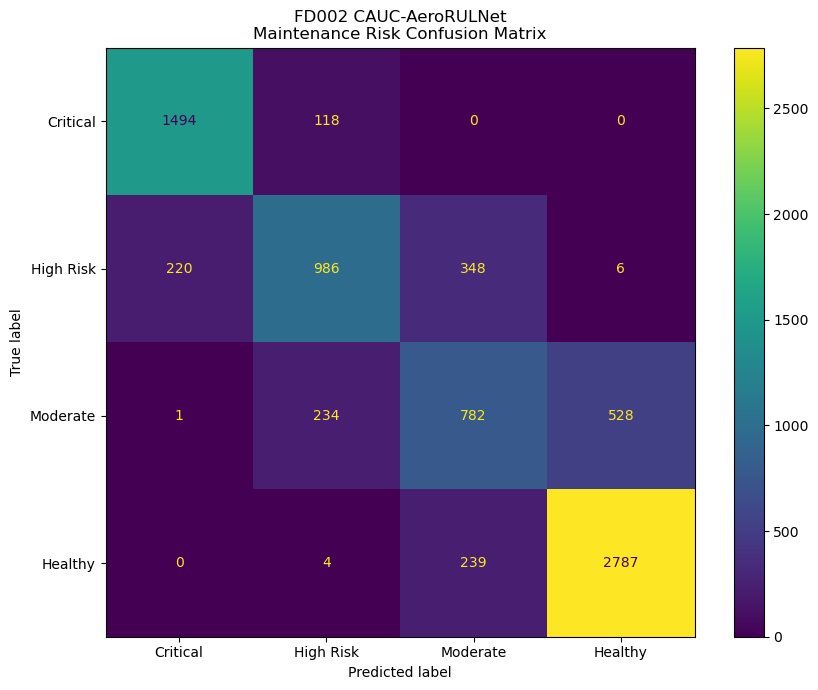

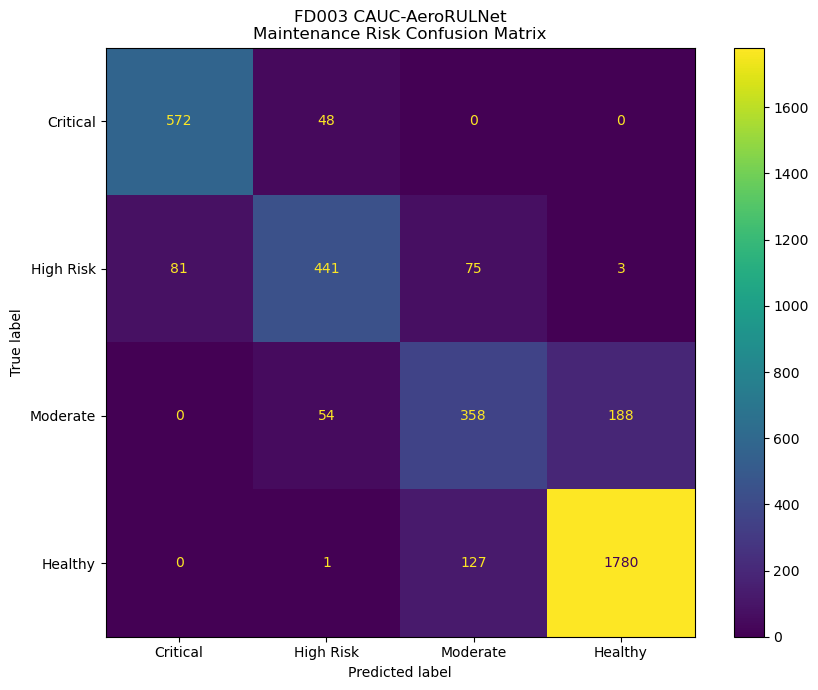

✅ Confusion matrices saved.


In [153]:
# ============================================================
# STEP 92
# SAVE CONFUSION MATRIX FIGURES
# ============================================================

from sklearn.metrics import (
    ConfusionMatrixDisplay
)


# ============================================================
# FD002
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 7)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=risk_order
)

disp.plot(
    ax=ax,
    values_format="d"
)

plt.title(
    "FD002 CAUC-AeroRULNet\n"
    "Maintenance Risk Confusion Matrix"
)

plt.tight_layout()

FD002_CM_PATH = os.path.join(
    DECISION_RESULT_DIR,
    "fd002_confusion_matrix.png"
)

plt.savefig(
    FD002_CM_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FD003
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 7)
)

disp_fd003 = ConfusionMatrixDisplay(
    confusion_matrix=cm_fd003,
    display_labels=risk_order
)

disp_fd003.plot(
    ax=ax,
    values_format="d"
)

plt.title(
    "FD003 CAUC-AeroRULNet\n"
    "Maintenance Risk Confusion Matrix"
)

plt.tight_layout()

FD003_CM_PATH = os.path.join(
    DECISION_RESULT_DIR,
    "fd003_confusion_matrix.png"
)

plt.savefig(
    FD003_CM_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print(
    "✅ Confusion matrices saved."
)

In [154]:
# ============================================================
# STEP 93
# FINAL PROJECT PERFORMANCE SUMMARY
# ============================================================

final_project_summary = pd.DataFrame([

    {
        "Dataset": "FD002",

        "CAUC_MAE":
            10.469964,

        "CAUC_RMSE":
            13.462717,

        "CAUC_R2":
            0.891859,

        "BiLSTM_RMSE":
            14.169504,

        "RMSE_Improvement_%":
            fd002_improvement,

        "Decision_Accuracy":
            decision_accuracy,

        "Decision_Macro_F1":
            decision_f1,

        "Critical_Recall":
            classification_report_df.loc[
                "Critical",
                "recall"
            ]
    },

    {
        "Dataset": "FD003",

        "CAUC_MAE":
            8.556795,

        "CAUC_RMSE":
            11.314010,

        "CAUC_R2":
            0.926985,

        "BiLSTM_RMSE":
            11.366003,

        "RMSE_Improvement_%":
            fd003_improvement,

        "Decision_Accuracy":
            fd003_accuracy,

        "Decision_Macro_F1":
            fd003_f1,

        "Critical_Recall":
            fd003_report_df.loc[
                "Critical",
                "recall"
            ]
    }
])


print("=" * 85)
print("FINAL CAUC-AeroRULNet PROJECT SUMMARY")
print("=" * 85)

display(
    final_project_summary.round(4)
)

FINAL CAUC-AeroRULNet PROJECT SUMMARY


,Dataset,CAUC_MAE,CAUC_RMSE,CAUC_R2,BiLSTM_RMSE,RMSE_Improvement_%,Decision_Accuracy,Decision_Macro_F1,Critical_Recall
0,FD002,10.4700,13.4627,0.8919,14.1695,4.9881,0.7808,0.7480,0.9268
1,FD003,8.5568,11.3140,0.9270,11.3660,0.4574,0.8452,0.8012,0.9226


In [155]:
# ============================================================
# STEP 94
# SAVE FINAL PROJECT SUMMARY
# ============================================================

FINAL_SUMMARY_PATH = os.path.join(
    PROJECT_DIR,
    "results",
    "final_project_summary.csv"
)


final_project_summary.to_csv(
    FINAL_SUMMARY_PATH,
    index=False
)


print(
    "✅ Final project summary saved:"
)

print(
    FINAL_SUMMARY_PATH
)

✅ Final project summary saved:
D:\IST\Aircraft_Engine_RUL\results\final_project_summary.csv
